# Unsupervised Clustering-Based Hyperspectral Band Selection
## K-means vs. Agglomerative Hierarchical Clustering on the DIPCOMA TrainVal dataset

**Section 1 — Project title and objectives**

A hyperspectral image (HSI) is a cube $X \in \mathbb{R}^{H\times W\times B}$: $H\times W$ pixels, each with $B$ spectral measurements (bands). Neighbouring bands are usually highly correlated, so many bands carry repeated information. **Band selection** keeps $K<B$ *original* bands and discards the rest.

This notebook implements **exactly two independent, unsupervised models**:

| | Model A | Model B |
|---|---|---|
| Algorithm | K-means on bands | Agglomerative hierarchical clustering on bands |
| Output | $K$ original band indices | $K$ original band indices |

and compares them under **identical** conditions (same cube, preprocessing, valid-band policy, band counts $K$, reconstruction baseline, classifier and metrics).

**Out of scope on purpose:** ranking-based selection, clustering+ranking hybrids, PCA/feature extraction, autoencoders, evolutionary search. Ground-truth labels are **never** used for clustering or band selection — only (separately) for downstream classification evaluation.

**How to use this notebook (beginner guide)**
1. Run cells top to bottom. Each section starts with a Markdown cell explaining *what / why / math / expected output*.
2. After **Section 4** (dataset inspection) read the printed report. If auto-detection chose the wrong file, axis order or label file, change the matching entry in the `CONFIG` cell and re-run from there.
3. Results are cached in the output folder, so after a Kaggle restart you can re-run and finished experiments are loaded instead of recomputed.

**Nothing in this notebook is a pre-computed result.** Every number you see is produced when *you* run it on the real data.

## Section 2 — Research-paper methodology and scope

**Primary reference:** Vaddi, R., Phaneendra Kumar, B.L.N., Manoharan, P., Agilandeeswari, L., Sangeetha, V. (2024). *Strategies for dimensionality reduction in hyperspectral remote sensing: A comprehensive overview.* Egyptian Journal of Remote Sensing and Space Sciences 27, 82–92. DOI: 10.1016/j.ejrs.2024.01.005.

### What the review paper explicitly states (Section 2.1 and Table 1)
* Group-wise band selection **separates bands into groups (clusters), then elects one band from each cluster**, using criteria such as *closeness to the cluster centre* and *information entropy (IE)*.
* These methods **consider interaction between bands** (unlike ranking methods, which evaluate bands independently).
* It lists, as examples, hierarchical clustering (Usó et al., 2007), Ward's linkage using divergence (**WaLuDi**) and using mutual information (**WaLuMI**), unsupervised **K-means** (Ahmad et al., 2011) and kernel K-means (Imbiriba et al., 2015).
* Stated advantages (Table 1): can help discard noisy bands/outliers; organise bands into coherent sets. Stated disadvantages: sensitive to the choice of primary cluster centres; repeated calculations raise computational load. Section 2.1 also warns that the band chosen in a cluster *may not be discriminative with respect to the whole data*.
* Eq. (3) of the paper counts the ways to partition $m$ bands into $n$ groups (Stirling number of the second kind) — which is why exhaustive search is infeasible and heuristics such as K-means / agglomeration are used.

### What the review paper does **not** provide (so it is *not* attributed to the paper)
Formulas for K-means or Ward linkage; which distance/similarity to use; normalisation; how to choose the number of clusters; the exact formulations of WaLuDi / WaLuMI; any reconstruction protocol; definitions of PSNR/SSIM/SAM/MAE/entropy/redundancy/mean spectral divergence. The review *reports* Mean Spectral Divergence values for one method but gives no formula.

### Classification of every decision in this notebook
| Item | Origin |
|---|---|
| Cluster bands, pick one representative per cluster | **Paper principle** (Sec. 2.1) |
| Representative = band closest to cluster centre | **Paper principle** (named criterion) + our concrete definition |
| Entropy-based representative | **Paper principle** (named criterion), our concrete definition; reported *separately* |
| Lloyd's K-means with k-means++ init (scikit-learn) | Standard ML practice |
| Ward / average / complete / single linkage (SciPy) | Standard ML practice |
| z-score each band, unit-norm rows, Euclidean distance (≡ correlation distance) | **Our implementation decision** (justified in Section 7) |
| Linear spectral interpolation as reconstruction baseline | **Our evaluation decision** (not part of either clustering model) |
| Metric definitions (Sections 16–18) | Standard definitions / our explicit choices |

**Ward linkage here is *standard* Ward linkage on Euclidean band distances. It is NOT WaLuDi or WaLuMI**, whose formulations are not given in the review. This notebook never claims to reproduce them.

### Supporting literature table (project rule: keep a literature comparison table)
Only papers actually supplied to this project are filled in. Papers that the review merely cites (Ahmad 2011, Usó 2007, …) were **not read directly**, so their fields are intentionally left unfilled rather than guessed.

| Field | Vaddi et al. 2024 (primary) | Wang, Wang & Liu 2022 (supporting only — *not implemented*) |
|---|---|---|
| Title | Strategies for dimensionality reduction in hyperspectral remote sensing: a comprehensive overview | Correlation-Guided Ensemble Clustering for Hyperspectral Band Selection |
| Authors | Vaddi, Phaneendra Kumar, Manoharan, Agilandeeswari, Sangeetha | Wang W., Wang W., Liu H. |
| DOI / link | 10.1016/j.ejrs.2024.01.005 | 10.3390/rs14051156 |
| Methodology | Review/comparison of DR methods; taxonomy of band selection | Ensemble of K-means partitions + locally weighted co-association + adjacency-constrained agglomerative consensus (ILWEA) + manifold ranking |
| Clustering algorithm | Surveys group-wise (K-means, hierarchical, …) | K-means base clusterings, agglomerative consensus |
| Distance / similarity | Not specified for group-wise methods | Co-association similarity (not a raw band distance) |
| Representative selection | Closeness to centre, information entropy (named) | Manifold ranking (a ranking method — excluded from our project) |
| Datasets | Indian Pines, Univ. Pavia, Salinas (+KSC, Botswana listed) | Pavia Univ., Botswana, Pavia Centre |
| Metrics | OA, AA, κ, precision/recall/F1, run time | OA/AOA, κ with SVM and KNN |
| Limitations / relevance | Survey, no group-wise formulas; background and taxonomy for this project | Hybrid ensemble+ranking → outside our scope; used only as context (e.g. adjacent-band correlation, Hughes phenomenon) |

## Section 3 — Dataset download and setup

**What:** import libraries, define the configuration, and locate the dataset.
**Why:** one `CONFIG` dictionary holds every adjustable choice so experiments are reproducible and nothing is hard-coded deeper in the notebook.

**Where the data should be (Kaggle):** click *Add Data → search "dipcoma-trainval" (user krrishshandilya)* in the notebook sidebar. It then appears under `/kaggle/input/...`.
**On Colab / local:** either upload the files and set `CONFIG["data_root"]`, or use the Kaggle API **securely** — put `kaggle.json` in `~/.kaggle/` via Colab's file panel / secrets (never paste the token in a cell or commit it), then the optional `kagglehub` fallback below can download the dataset.

**Expected output:** library versions and the dataset root path.
**Common errors:** `Dataset not found` → add the dataset in the Kaggle sidebar or set `CONFIG["data_root"]`.

In [1]:
import os, sys, json, time, re, math, hashlib, warnings, platform, tracemalloc, subprocess
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import io as sio, ndimage
from scipy.cluster import hierarchy as sch
from scipy.spatial.distance import pdist, squareform
import sklearn
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, adjusted_rand_score, accuracy_score,
                             cohen_kappa_score, confusion_matrix, recall_score,
                             classification_report)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
import skimage
from skimage.metrics import structural_similarity
try:
    import psutil
except ImportError:
    psutil = None
try:
    import h5py
except ImportError:
    h5py = None

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| sklearn", sklearn.__version__, "| skimage", skimage.__version__, "| pandas", pd.__version__)
print("optional: psutil", psutil is not None, "| h5py", h5py is not None)

python 3.13.16 | numpy 2.1.3 | scipy 1.16.3 | sklearn 1.6.1 | skimage 0.25.2 | pandas 2.3.3
optional: psutil True | h5py True


In [2]:
# ===================== CONFIGURATION (edit here) =====================
CONFIG = dict(
    # ---- data location / format (leave None to auto-detect; fill after reading Section 4 output) ----
    data_root=None,            # folder containing the dataset
    kaggle_slug="krrishshandilya/dipcoma-trainval",
    try_kagglehub=True,        # fallback download if nothing is found locally (needs credentials/internet)
    image_path=None,           # explicit path of the hyperspectral file to use
    image_index=0,             # otherwise: index into the list of discovered cube files
    array_key=None,            # variable/dataset name inside .mat/.npz/.h5 files
    axis_order=None,           # e.g. "HWB", "BHW", "HBW" if auto-guess is wrong
    wavelengths=None,          # list of wavelengths (one per ORIGINAL band) to override auto-detection
    label_path=None, label_key=None, label_background=0,   # ground-truth map (H x W); 0 = unlabeled
    original_bits=None,        # None -> derived from the file dtype (e.g. uint16 -> 16)
    # ---- experiment design ----
    K_list=[5, 10, 15, 20, 25],        # numbers of retained bands (same for both models)
    retention_percent=None,            # alternative, e.g. [5,10,15,20,25]; overrides K_list if set
    seed=42,
    kmeans_seeds=[0, 1, 2, 3, 4],      # K-means repetitions (mean +/- std reported)
    kmeans_n_init=10,
    n_sample_pixels=100_000,           # pixels used to build the band feature matrix
    primary_linkage="ward",
    compare_linkages=["average", "complete", "single"],   # secondary ablation (Ward is primary)
    run_secondary=True,                # medoid/entropy representatives + linkage ablation
    secondary_n_seeds=2,
    # ---- preprocessing ----
    const_std_tol=1e-8,                # band is 'constant' if std <= tol * global data range
    drop_noisy_bands=False,            # noisy bands are only FLAGGED by default
    noise_z_thresh=3.5,
    # ---- metrics ----
    entropy_bins=256, divergence_bins=64, divergence_smoothing=0.5,
    rel_err_eps_frac=1e-4,             # |x| <= frac*data_range is excluded from relative error
    compute_ssim=True, measure_memory=True,
    # ---- classification (only if a valid label map exists) ----
    run_classification=True, train_fraction=0.2, max_labeled_pixels=30_000,
    svm_C=10.0, svm_kernel="rbf",
    # ---- diagnostics for choosing cluster count ----
    diag_k_step=2, diag_k_max=30, diag_n_init=3,
    use_cache=True,
)
# optional JSON override via environment variable (useful for automated runs)
if os.environ.get("HSI_CONFIG_OVERRIDE"):
    CONFIG.update(json.loads(os.environ["HSI_CONFIG_OVERRIDE"]))

OUT_ROOT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./")
OUT = OUT_ROOT / "hsi_band_selection_outputs"
DIRS = {n: OUT / n for n in ["figures", "tables", "selections", "cache", "reports", "config"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
FIG_DIR, TAB_DIR, SEL_DIR, CACHE_DIR, REP_DIR, CFG_DIR = (DIRS[k] for k in
    ["figures", "tables", "selections", "cache", "reports", "config"])
np.random.seed(CONFIG["seed"])

def savefig(name):
    p = FIG_DIR / f"{name}.png"
    plt.savefig(p, dpi=150, bbox_inches="tight")
    print("saved:", p)

print("Outputs will be written to:", OUT.resolve())

Outputs will be written to: /kaggle/working/hsi_band_selection_outputs


## Section 4 — Dataset inspection

**What:** list every file/folder, count file types, and try to read the shape and dtype of candidate hyperspectral files.
**Why:** we must not assume the dataset layout (project rule). Everything later uses what is *discovered* here.
**Expected output:** a directory summary, a table of candidate cube files with shape/dtype, and any label-like files.
**Verify:** the candidate list contains the file(s) you expect; shapes look like (H, W, B) or (B, H, W).

*If the dataset turns out to be organised differently from what these loaders support (e.g. image-level labels, a different file format), the report below will show it — send me that output and the loaders can be adapted instead of guessing.*

In [3]:
CUBE_EXTS = {".npy", ".npz", ".mat", ".h5", ".hdf5", ".tif", ".tiff", ".hdr"}
LABEL_PAT = re.compile(r"(gt|ground.?truth|label|mask|class|annot|seg|truth)", re.I)
ENVI_DTYPES = {1: np.uint8, 2: np.int16, 3: np.int32, 4: np.float32, 5: np.float64,
               12: np.uint16, 13: np.uint32, 14: np.int64, 15: np.uint64}

def locate_dataset():
    if CONFIG["data_root"]:
        return Path(CONFIG["data_root"])
    if os.environ.get("DIPCOMA_ROOT"):
        return Path(os.environ["DIPCOMA_ROOT"])
    k = Path("/kaggle/input")
    if k.exists():
        hits = [p for p in k.rglob("*") if p.is_dir() and "dipcoma" in p.name.lower()]
        if hits:
            return sorted(hits, key=lambda p: len(p.parts))[0]
        subs = [p for p in k.iterdir() if p.is_dir()]
        if len(subs) == 1:
            return subs[0]
    if CONFIG["try_kagglehub"]:
        try:
            import kagglehub
            return Path(kagglehub.dataset_download(CONFIG["kaggle_slug"]))
        except Exception as e:
            print("kagglehub download failed:", repr(e))
    return None

DATA_ROOT = locate_dataset()
if DATA_ROOT is None or not DATA_ROOT.exists():
    raise FileNotFoundError(
        "Dataset not found. On Kaggle: Add Data -> 'dipcoma-trainval'. Elsewhere: set CONFIG['data_root'] "
        "to the folder containing the files (do NOT put API tokens in this notebook).")
print("DATA_ROOT =", DATA_ROOT)

all_files = sorted([p for p in DATA_ROOT.rglob("*") if p.is_file()])
print(f"\nTotal files: {len(all_files)} | total size: {sum(p.stat().st_size for p in all_files)/2**20:.1f} MiB")
ext_counts = pd.Series([p.suffix.lower() or "<none>" for p in all_files]).value_counts()
print("\nFile extensions:\n", ext_counts.to_string())
dir_counts = pd.Series([str(p.parent.relative_to(DATA_ROOT)) for p in all_files]).value_counts()
print("\nFiles per directory (top 25):\n", dir_counts.head(25).to_string())
print("\nFirst 30 files:")
for p in all_files[:30]:
    print("  ", p.relative_to(DATA_ROOT), f"({p.stat().st_size/2**20:.2f} MiB)")

DATA_ROOT = /kaggle/input/datasets/krrishshandilya/dipcoma-trainval

Total files: 1129 | total size: 7294.2 MiB

File extensions:
 .npy     1122
.csv        3
.py         2
.json       1
.png        1

Files per directory (top 25):
 dataset/train/amazon_manaus          66
dataset/train/black_forest           66
dataset/train/atacama                66
dataset/train/delhi                  66
dataset/train/central_valley         66
dataset/train/serengeti              66
dataset/train/sundarbans             66
dataset/train/iceland_vatnajokull    66
dataset/train/iowa                   66
dataset/train/lake_victoria          66
dataset/train/maldives               66
dataset/train/punjab                 66
dataset/train/sahara_algeria         66
dataset/val/tokyo_bay                66
dataset/val/gobi                     66
dataset/train/swiss_alps             66
dataset/train/central_borneo         33
dataset/val/murray_darling           33
.                                     3
code   

In [4]:
# ---------- generic readers (no assumptions about dataset structure) ----------
def parse_envi_header(hdr_path):
    txt = Path(hdr_path).read_text(errors="ignore")
    txt = re.sub(r"\{([^}]*)\}", lambda m: "{" + m.group(1).replace("\n", " ") + "}", txt)
    meta = {}
    for line in txt.splitlines():
        if "=" in line:
            k, v = line.split("=", 1)
            meta[k.strip().lower()] = v.strip()
    return meta

def _floats_from_braces(s):
    return [float(t) for t in s.strip("{} ").split(",") if t.strip()]

def load_envi(hdr_path):
    m = parse_envi_header(hdr_path)
    samples, lines, bands = int(m["samples"]), int(m["lines"]), int(m["bands"])
    dt = np.dtype(ENVI_DTYPES[int(m["data type"])]).newbyteorder(">" if int(m.get("byte order", 0)) == 1 else "<")
    inter, off = m.get("interleave", "bsq").lower(), int(m.get("header offset", 0))
    stem = Path(hdr_path).with_suffix("")
    cands = [stem] + [p for p in stem.parent.glob(stem.name + ".*") if p.suffix.lower() != ".hdr"]
    data_path = next((c for c in cands if c.exists() and c.is_file()), None)
    if data_path is None:
        raise FileNotFoundError(f"ENVI data file for {hdr_path} not found")
    mm = np.memmap(data_path, dtype=dt, mode="r", offset=off)
    shapes = {"bsq": ((bands, lines, samples), "BHW"), "bil": ((lines, bands, samples), "HBW"),
              "bip": ((lines, samples, bands), "HWB")}
    shp, layout = shapes[inter]
    wl = _floats_from_braces(m["wavelength"]) if "wavelength" in m else None
    return dict(arr=mm.reshape(shp), layout=layout, wavelengths=wl, key=None, source=str(data_path))

def _arrays_from_container(path):
    ext, out = path.suffix.lower(), {}
    if ext == ".npz":
        z = np.load(path, allow_pickle=False)
        out = {k: z[k] for k in z.files}
    elif ext == ".mat":
        try:
            d = sio.loadmat(path)
            out = {k: v for k, v in d.items() if not k.startswith("__") and isinstance(v, np.ndarray)}
        except NotImplementedError:
            if h5py is None:
                raise RuntimeError("MATLAB v7.3 file needs h5py (pip install h5py)")
            print("WARNING: MATLAB v7.3 file - axes are stored reversed; set CONFIG['axis_order'] if needed.")
            with h5py.File(path, "r") as f:
                f.visititems(lambda n, o: out.__setitem__(n, o[()]) if isinstance(o, h5py.Dataset) else None)
    elif ext in (".h5", ".hdf5"):
        if h5py is None:
            raise RuntimeError("HDF5 file needs h5py (pip install h5py)")
        with h5py.File(path, "r") as f:
            f.visititems(lambda n, o: out.__setitem__(n, o[()]) if isinstance(o, h5py.Dataset) else None)
    out = {k: np.asarray(v) for k, v in out.items() if np.asarray(v).dtype.kind in "biuf"}
    return out

def _find_wavelengths(d):
    for k, v in d.items():
        if re.search(r"wave|lambda|^wl", k, re.I) and v.ndim <= 2 and v.size > 3:
            return [float(x) for x in np.ravel(v)]
    return None

def load_cube_file(path, array_key=None):
    """Return dict(arr, layout, wavelengths, key, source). arr is 3-D (not yet reordered)."""
    path, ext = Path(path), Path(path).suffix.lower()
    if ext == ".hdr":
        return load_envi(path)
    if ext == ".npy":
        return dict(arr=np.load(path, mmap_mode="r"), layout=None, wavelengths=None, key=None, source=str(path))
    if ext in (".tif", ".tiff"):
        try:
            import rasterio
            with rasterio.open(path) as ds:
                return dict(arr=ds.read(), layout="BHW", wavelengths=None, key=None, source=str(path))
        except ImportError:
            import tifffile
            return dict(arr=tifffile.imread(path), layout=None, wavelengths=None, key=None, source=str(path))
    d = _arrays_from_container(path)
    three = {k: v for k, v in d.items() if v.ndim == 3}
    if not three:
        raise ValueError(f"No 3-D numeric array in {path.name}; arrays found: { {k: v.shape for k, v in d.items()} }")
    key = array_key if array_key in three else max(three, key=lambda k: three[k].size)
    return dict(arr=three[key], layout=None, wavelengths=_find_wavelengths(d), key=key, source=f"{path}::{key}")

def adjacent_slice_corr(arr, axis, n_pairs=12, n_pix=20000):
    """Mean Pearson correlation between neighbouring slices along `axis` (advisory test for the spectral axis)."""
    n = arr.shape[axis]
    if n < 3: return -1.0
    rg = np.random.default_rng(0); cs = []
    for i in np.unique(np.linspace(0, n - 2, min(n_pairs, n - 1)).astype(int)):
        a = np.asarray(np.take(arr, i, axis=axis), dtype=np.float64).ravel()
        b = np.asarray(np.take(arr, i + 1, axis=axis), dtype=np.float64).ravel()
        idx = rg.choice(a.size, size=min(n_pix, a.size), replace=False); a, b = a[idx], b[idx]
        ok = np.isfinite(a) & np.isfinite(b)
        if ok.sum() > 10 and a[ok].std() > 0 and b[ok].std() > 0: cs.append(np.corrcoef(a[ok], b[ok])[0, 1])
    return float(np.mean(cs)) if cs else -1.0

def guess_layout(arr):
    """Spectral axis = the axis whose neighbouring slices are most correlated; ties -> common H,W,B convention."""
    c = [adjacent_slice_corr(arr, ax) for ax in range(3)]
    print("  adjacent-slice correlation along axis 0/1/2 =", [round(v, 4) for v in c])
    best = int(np.argmax(c))
    if best != 2 and c[best] - c[2] < 0.02:      # not clearly better than the last axis -> default HWB
        best = 2
    return {0: "BHW", 1: "HBW", 2: "HWB"}[best]

def to_bhw(arr, layout):
    perm = [layout.index(c) for c in "BHW"]
    return np.transpose(arr, perm)

def inspect_file(p):
    try:
        if p.suffix.lower() == ".hdr":
            m = parse_envi_header(p)
            return dict(shape=(int(m["bands"]), int(m["lines"]), int(m["samples"])), dtype=f"envi type {m['data type']}", note="ENVI header")
        r = load_cube_file(p)
        return dict(shape=tuple(r["arr"].shape), dtype=str(r["arr"].dtype),
                    note=f"key={r['key']}" if r["key"] else "")
    except Exception as e:
        return dict(shape=None, dtype=None, note=f"not a readable cube ({type(e).__name__}: {str(e)[:70]})")

cube_files_all = [p for p in all_files if p.suffix.lower() in CUBE_EXTS]
print(f"Files with a readable-format extension: {len(cube_files_all)}")
MAX_SCAN = 20
scan, not_cubes = [], set()
for p in cube_files_all[:MAX_SCAN]:
    info = inspect_file(p); info.update(file=str(p.relative_to(DATA_ROOT)))
    if info["shape"] is None or len(info["shape"]) != 3:
        not_cubes.add(p); info["note"] = (info["note"] + " | not a 3-D array -> not a cube candidate").strip(" |")
    scan.append(info)
# files that are not 3-D arrays (e.g. 2-D label maps) are excluded; unscanned files are kept unless their name looks like a label file
cube_files = [p for p in cube_files_all if p not in not_cubes and not (p not in cube_files_all[:MAX_SCAN] and LABEL_PAT.search(p.name))]
for i, p in enumerate(cube_files):
    for info in scan:
        if info["file"] == str(p.relative_to(DATA_ROOT)): info["index"] = i
if scan:
    print(pd.DataFrame(scan).reindex(columns=["index", "file", "shape", "dtype", "note"]).astype({"index": "Int64"}).to_string(index=False))
print(f"\nCube candidates (selectable with CONFIG['image_index']): {len(cube_files)}")
if len(cube_files_all) > MAX_SCAN:
    print(f"... only the first {MAX_SCAN} of {len(cube_files_all)} files were scanned. Pick a file with CONFIG['image_index'] / CONFIG['image_path'].")

label_like = [p for p in all_files if LABEL_PAT.search(p.name)]
print(f"\nLabel-like file names: {len(label_like)}")
for p in label_like[:15]:
    print("  ", p.relative_to(DATA_ROOT))
split_dirs = sorted({part for p in all_files for part in p.relative_to(DATA_ROOT).parts[:-1]
                     if re.search(r"train|val|test", part, re.I)})
print("Folder names hinting at train/val/test splits:", split_dirs or "none found")

Files with a readable-format extension: 1122
 index                                                 file          shape  dtype note
     0 dataset/train/amazon_manaus/20MRB_20250730_r0_c9.npy (13, 512, 512) uint16     
     1 dataset/train/amazon_manaus/20MRB_20250730_r1_c2.npy (13, 512, 512) uint16     
     2 dataset/train/amazon_manaus/20MRB_20250730_r1_c3.npy (13, 512, 512) uint16     
     3 dataset/train/amazon_manaus/20MRB_20250730_r1_c4.npy (13, 512, 512) uint16     
     4 dataset/train/amazon_manaus/20MRB_20250730_r2_c9.npy (13, 512, 512) uint16     
     5 dataset/train/amazon_manaus/20MRB_20250730_r3_c4.npy (13, 512, 512) uint16     
     6 dataset/train/amazon_manaus/20MRB_20250730_r3_c6.npy (13, 512, 512) uint16     
     7 dataset/train/amazon_manaus/20MRB_20250730_r3_c9.npy (13, 512, 512) uint16     
     8 dataset/train/amazon_manaus/20MRB_20250730_r4_c2.npy (13, 512, 512) uint16     
     9 dataset/train/amazon_manaus/20MRB_20250730_r4_c5.npy (13, 512, 512) uint16    

## Section 5 — Data loading

**What:** load one hyperspectral cube, convert it to a canonical internal layout, and detect wavelengths and bit depth.
**Why:** all algorithms need a known layout. Internally we store the cube **band-first** as `XB[b] = band image (H×W)`, because clustering treats *each band as one object*.
**Math:** the cube $X\in\mathbb{R}^{H\times W\times B}$ is stored as $B$ images $X_b \in \mathbb{R}^{H\times W}$.
**Expected output:** the chosen file, detected axis order, $H$, $W$, $B$, dtype, bit depth, wavelength availability.
**Verify:** the printed $(H,W,B)$ match what you expect. If the axis order was only *guessed*, check that $B$ is the spectral axis and otherwise set `CONFIG["axis_order"]`.

*Note:* if the dataset contains several images, this notebook analyses **one** cube (chosen by `image_index`) so that both methods see exactly the same data.

In [5]:
if CONFIG["image_path"]:
    IMG_PATH = Path(CONFIG["image_path"])
else:
    assert cube_files, "No candidate hyperspectral files were found - see the Section 4 report."
    IMG_PATH = cube_files[CONFIG["image_index"]]
print("Using file:", IMG_PATH)

loaded = load_cube_file(IMG_PATH, CONFIG["array_key"])
raw = loaded["arr"]
assert raw.ndim == 3, f"expected a 3-D cube, got shape {raw.shape}"
layout = CONFIG["axis_order"] or loaded["layout"]
layout_source = "config" if CONFIG["axis_order"] else ("file metadata" if loaded["layout"] else "GUESSED")
if layout is None:
    layout, layout_source = guess_layout(raw), "GUESSED (axis with most correlated neighbouring slices = spectral)"
print(f"stored shape = {raw.shape} | axis order = {layout} ({layout_source}) | dtype = {raw.dtype}")
if "GUESSED" in layout_source:
    print("  >> This is only a heuristic. Check that B (printed below) is really the number of spectral bands;")
    print("     otherwise set CONFIG['axis_order'] (e.g. 'HWB', 'BHW') and re-run from this cell.")

ORIG_DTYPE = raw.dtype
ORIG_BITS = int(CONFIG["original_bits"] or ORIG_DTYPE.itemsize * 8)

XB = np.ascontiguousarray(to_bhw(raw, layout)).astype(np.float32)     # (B, H, W)
del raw
B_TOTAL, H, W = XB.shape
print(f"H = {H}, W = {W}, B = {B_TOTAL}   | stored dtype = {ORIG_DTYPE} -> assumed original bit depth = {ORIG_BITS} bits/sample")
print(f"cube in memory: {XB.nbytes/2**20:.1f} MiB (float32 working copy)")

# wavelengths: config > file metadata > unavailable
WL_ORIG = CONFIG["wavelengths"] or loaded["wavelengths"]
if WL_ORIG is not None:
    WL_ORIG = np.asarray(WL_ORIG, float)
    if WL_ORIG.size != B_TOTAL:
        print(f"WARNING: {WL_ORIG.size} wavelengths for {B_TOTAL} bands -> ignoring wavelengths")
        WL_ORIG = None
print("wavelength information:", "available" if WL_ORIG is not None else "NOT available (band index will be used as the spectral coordinate)")
if WL_ORIG is not None:
    print(f"  range {WL_ORIG.min():.4g} .. {WL_ORIG.max():.4g}")

Using file: /kaggle/input/datasets/krrishshandilya/dipcoma-trainval/dataset/train/amazon_manaus/20MRB_20250730_r0_c9.npy
  adjacent-slice correlation along axis 0/1/2 = [0.8028, 0.9895, 0.9893]
stored shape = (13, 512, 512) | axis order = HWB (GUESSED (axis with most correlated neighbouring slices = spectral)) | dtype = uint16
  >> This is only a heuristic. Check that B (printed below) is really the number of spectral bands;
     otherwise set CONFIG['axis_order'] (e.g. 'HWB', 'BHW') and re-run from this cell.
H = 13, W = 512, B = 512   | stored dtype = uint16 -> assumed original bit depth = 16 bits/sample
cube in memory: 13.0 MiB (float32 working copy)
wavelength information: NOT available (band index will be used as the spectral coordinate)


In [6]:
# ---------- ground-truth label discovery (labels are used ONLY for downstream classification) ----------
def read_label_candidate(path, key=None):
    ext = path.suffix.lower()
    try:
        if ext == ".npy":
            a = np.load(path, mmap_mode="r")
            return {None: np.asarray(a)}
        if ext in (".npz", ".mat", ".h5", ".hdf5"):
            return {k: v for k, v in _arrays_from_container(path).items() if v.ndim == 2}
        if ext in (".tif", ".tiff", ".png", ".bmp"):
            from skimage import io as skio
            a = skio.imread(path)
            return {None: np.asarray(a)} if a.ndim == 2 else {}
    except Exception:
        return {}
    return {}

def find_labels(h, w):
    if CONFIG["label_path"]:
        cands = [Path(CONFIG["label_path"])]
    else:
        cands = [p for p in label_like if p != IMG_PATH]
        cands.sort(key=lambda p: (p.stem.lower() != IMG_PATH.stem.lower() and IMG_PATH.stem.lower() not in p.stem.lower(), len(p.name)))
    for p in cands:
        for k, a in read_label_candidate(p, CONFIG["label_key"]).items():
            if CONFIG["label_key"] and k != CONFIG["label_key"]:
                continue
            if a.shape == (h, w) and np.all(np.mod(a, 1) == 0):
                u = np.unique(a)
                if 2 <= len(u) <= 512:
                    return a.astype(np.int64), f"{p}" + (f"::{k}" if k else "")
    return None, None

LABELS, LABEL_SRC = find_labels(H, W)
if LABELS is None:
    print("No valid pixel-level label map with shape (H, W) found -> classification metrics (OA/AA/Kappa) will be N/A.")
    print("(If labels exist elsewhere/in another form, set CONFIG['label_path'] / ['label_key'].)")
else:
    vals, cnts = np.unique(LABELS, return_counts=True)
    print("Label map:", LABEL_SRC)
    print("  class values and pixel counts:", dict(zip(vals.tolist(), cnts.tolist())))
    print(f"  background value ignored: {CONFIG['label_background']}")

No valid pixel-level label map with shape (H, W) found -> classification metrics (OA/AA/Kappa) will be N/A.
(If labels exist elsewhere/in another form, set CONFIG['label_path'] / ['label_key'].)


## Section 6 — Preprocessing

**What:** (1) find invalid pixels (NaN/Inf), (2) compute per-band statistics, (3) detect constant bands, (4) flag likely noisy bands, (5) fix the **valid-band policy** and **fixed data range** shared by both models and all metrics.

**Why each step**
* *Invalid pixels:* a pixel with any NaN/Inf in any band is excluded from every statistic and metric (mask $M$), and its values are set to 0 so arrays stay finite.
* *Constant bands:* a band with zero variance has undefined correlation ($0/0$) and carries no information → excluded from clustering **and** from evaluation (same policy for both models). Documented in the output.
* *Noisy bands (optional):* crude proxy $\rho_b=\sigma(\text{residual})/\sigma(\text{band})$ where residual = band − 3×3 mean-filtered band; bands with a robust z-score above the threshold are **flagged, not removed** (`drop_noisy_bands=False`), because removing bands silently would bias the comparison. This is a heuristic, not a calibrated SNR.
* *Data range:* $\text{DR}=\max-\min$ over valid pixels and kept bands, computed **once**. It is the fixed `MAX` for PSNR and `data_range` for SSIM for *both* methods.

**Expected output:** counts of invalid pixels, constant bands, flagged noisy bands, kept bands $B_v$, and the fixed data range.
**Verify:** assertions at the end of the cell pass (no NaN/Inf left, $B_v\ge 3$).

In [7]:
# 1) invalid values -> pixel mask
MASK = np.ones((H, W), dtype=bool)
for b in range(B_TOTAL):
    MASK &= np.isfinite(XB[b])
n_invalid = int((~MASK).sum())
if n_invalid:
    np.nan_to_num(XB, copy=False, nan=0.0, posinf=0.0, neginf=0.0)
print(f"Invalid pixels (any NaN/Inf in any band): {n_invalid} of {H*W} ({100*n_invalid/(H*W):.3f} %)")
assert MASK.sum() > 0, "no valid pixels"
assert np.isfinite(XB).all()

# 2) per-band statistics on valid pixels
stats = pd.DataFrame({
    "band": np.arange(B_TOTAL),
    "min":  [XB[b][MASK].min() for b in range(B_TOTAL)],
    "max":  [XB[b][MASK].max() for b in range(B_TOTAL)],
    "mean": [XB[b][MASK].mean() for b in range(B_TOTAL)],
    "std":  [XB[b][MASK].std() for b in range(B_TOTAL)],
})
GLOBAL_RANGE_ALL = float(stats["max"].max() - stats["min"].min())
assert GLOBAL_RANGE_ALL > 0, "the whole cube is constant"

# 3) constant bands
const_mask = stats["std"].values <= CONFIG["const_std_tol"] * GLOBAL_RANGE_ALL
CONST_BANDS = np.flatnonzero(const_mask)
print(f"Constant bands (std <= {CONFIG['const_std_tol']:g} x range): {len(CONST_BANDS)} -> {CONST_BANDS.tolist()}")

# 4) noisy-band flags (heuristic)
def noise_ratio(b):
    x = XB[b]; sm = ndimage.uniform_filter(x, size=3, mode="nearest")
    return float((x - sm)[MASK].std() / (x[MASK].std() + 1e-12))
stats["noise_ratio"] = [np.nan if const_mask[b] else noise_ratio(b) for b in range(B_TOTAL)]
nr = stats["noise_ratio"].dropna().values
med = np.median(nr); mad = np.median(np.abs(nr - med)) + 1e-12
stats["noise_z"] = 0.6745 * (stats["noise_ratio"] - med) / mad
NOISY_FLAGGED = stats.index[(stats["noise_z"] > CONFIG["noise_z_thresh"]).fillna(False)].values
print(f"Flagged as likely noisy (robust z > {CONFIG['noise_z_thresh']}): {len(NOISY_FLAGGED)} -> {NOISY_FLAGGED.tolist()}")
print("  (flag only; removed from the analysis only if CONFIG['drop_noisy_bands'] = True)")

# 5) valid-band policy (identical for both models and all metrics)
drop = set(CONST_BANDS.tolist()) | (set(NOISY_FLAGGED.tolist()) if CONFIG["drop_noisy_bands"] else set())
VALID_IDX = np.array([b for b in range(B_TOTAL) if b not in drop])
B_V = len(VALID_IDX)
assert B_V >= 3, "too few valid bands"
DR = float(stats.loc[VALID_IDX, "max"].max() - stats.loc[VALID_IDX, "min"].min())   # fixed data range
REL_EPS = CONFIG["rel_err_eps_frac"] * DR

# spectral coordinate for interpolation
if WL_ORIG is not None:
    COORD = WL_ORIG[VALID_IDX].astype(float)
    if np.all(np.diff(COORD) < 0):
        COORD = -COORD
    if not np.all(np.diff(COORD) > 0):
        print("WARNING: wavelengths are not strictly monotonic -> falling back to band-index coordinate")
        COORD, COORD_KIND = VALID_IDX.astype(float), "band index (wavelengths non-monotonic)"
    else:
        COORD_KIND = "wavelength"
else:
    COORD, COORD_KIND = VALID_IDX.astype(float), "band index (no wavelength info)"

WIN = min(7, H, W); WIN = WIN - 1 if WIN % 2 == 0 else WIN
SSIM_OK = CONFIG["compute_ssim"] and WIN >= 3

print(f"\nValid bands B_v = {B_V} of B = {B_TOTAL} | fixed data range DR = {DR:.6g} (PSNR MAX / SSIM data_range)")
print(f"Spectral coordinate for interpolation: {COORD_KIND} | SSIM window = {WIN} | SSIM enabled = {SSIM_OK}")
stats.to_csv(TAB_DIR / "band_statistics.csv", index=False)

Invalid pixels (any NaN/Inf in any band): 0 of 6656 (0.000 %)
Constant bands (std <= 1e-08 x range): 0 -> []
Flagged as likely noisy (robust z > 3.5): 0 -> []
  (flag only; removed from the analysis only if CONFIG['drop_noisy_bands'] = True)

Valid bands B_v = 512 of B = 512 | fixed data range DR = 6199 (PSNR MAX / SSIM data_range)
Spectral coordinate for interpolation: band index (no wavelength info) | SSIM window = 7 | SSIM enabled = True


In [8]:
# ---------- dataset inspection report (saved) ----------
report = dict(
    data_root=str(DATA_ROOT), image_file=str(IMG_PATH), n_files=len(all_files),
    H=H, W=W, B_total=B_TOTAL, axis_order=layout, axis_order_source=layout_source,
    stored_dtype=str(ORIG_DTYPE), assumed_bits_per_sample=ORIG_BITS,
    value_min=float(stats["min"].min()), value_max=float(stats["max"].max()),
    wavelengths_available=WL_ORIG is not None,
    invalid_pixels=n_invalid, constant_bands=CONST_BANDS.tolist(), noisy_flagged=NOISY_FLAGGED.tolist(),
    valid_bands=B_V, data_range_DR=DR, labels_available=LABELS is not None, label_source=LABEL_SRC,
    n_candidate_cube_files=len(cube_files), split_folders=split_dirs,
)
(REP_DIR / "dataset_inspection_report.json").write_text(json.dumps(report, indent=2))
print(json.dumps(report, indent=2))

{
  "data_root": "/kaggle/input/datasets/krrishshandilya/dipcoma-trainval",
  "image_file": "/kaggle/input/datasets/krrishshandilya/dipcoma-trainval/dataset/train/amazon_manaus/20MRB_20250730_r0_c9.npy",
  "n_files": 1129,
  "H": 13,
  "W": 512,
  "B_total": 512,
  "axis_order": "HWB",
  "axis_order_source": "GUESSED (axis with most correlated neighbouring slices = spectral)",
  "stored_dtype": "uint16",
  "assumed_bits_per_sample": 16,
  "value_min": 1007.0,
  "value_max": 7206.0,
  "wavelengths_available": false,
  "invalid_pixels": 0,
  "constant_bands": [],
  "noisy_flagged": [],
  "valid_bands": 512,
  "data_range_DR": 6199.0,
  "labels_available": false,
  "label_source": null,
  "n_candidate_cube_files": 1122,
  "split_folders": [
    "central_valley",
    "train",
    "val"
  ]
}


saved: /kaggle/working/hsi_band_selection_outputs/figures/01_original_band_examples.png


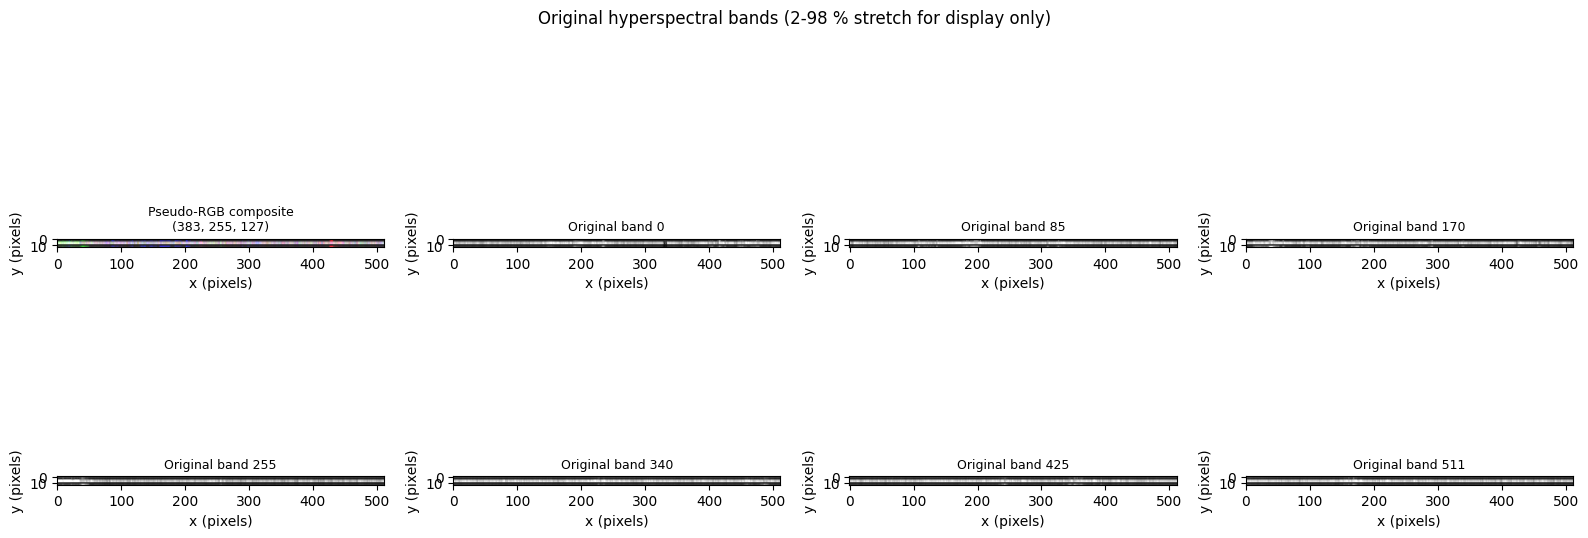

Pseudo-RGB rule: no usable wavelengths: bands at 75%/50%/25% of the valid index range (false colour, for visualisation only)
saved: /kaggle/working/hsi_band_selection_outputs/figures/02_mean_spectrum_and_std.png


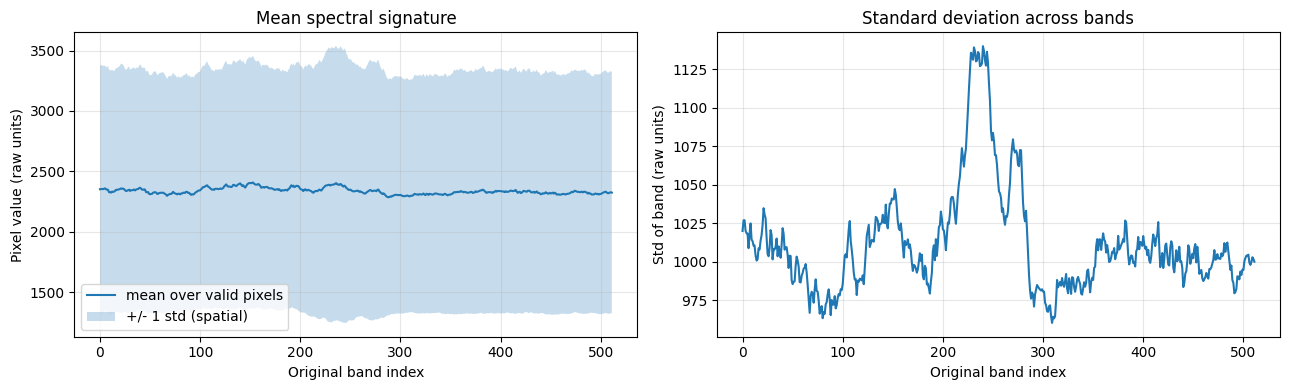

Interpretation: the mean spectrum shows the overall spectral shape; red lines (if any) mark bands flagged as noisy by the heuristic.


In [9]:
# ---------- exploratory figures: band examples, pseudo-RGB, mean spectrum, std per band ----------
def stretch(x, lo=2, hi=98):
    a, b = np.percentile(x[MASK], [lo, hi]); return np.clip((x - a) / (b - a + 1e-12), 0, 1)

def pseudo_rgb_bands():
    if WL_ORIG is not None:
        wl = WL_ORIG[VALID_IDX]
        scale = 1000.0 if wl.max() < 10 else 1.0        # micrometres -> nm
        if (wl * scale).min() < 700 and (wl * scale).max() > 600:
            tgt = np.array([650, 550, 470])
            pos = [int(np.argmin(np.abs(wl * scale - t))) for t in tgt]
            return pos, "nearest valid bands to 650/550/470 nm"
    pos = [int(0.75 * (B_V - 1)), int(0.5 * (B_V - 1)), int(0.25 * (B_V - 1))]
    return pos, "no usable wavelengths: bands at 75%/50%/25% of the valid index range (false colour, for visualisation only)"

pos_rgb, rgb_note = pseudo_rgb_bands()
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
rgb = np.dstack([stretch(XB[VALID_IDX[p]]) for p in pos_rgb])
ax[0, 0].imshow(rgb); ax[0, 0].set_title("Pseudo-RGB composite\n(" + ", ".join(str(VALID_IDX[p]) for p in pos_rgb) + ")", fontsize=9)
ex = np.linspace(0, B_V - 1, 7).astype(int)
for a, p in zip(ax.ravel()[1:], ex):
    a.imshow(stretch(XB[VALID_IDX[p]]), cmap="gray"); a.set_title(f"Original band {VALID_IDX[p]}", fontsize=9)
for a in ax.ravel(): a.set_xlabel("x (pixels)"); a.set_ylabel("y (pixels)"); a.grid(False)
plt.suptitle("Original hyperspectral bands (2-98 % stretch for display only)")
plt.tight_layout(); savefig("01_original_band_examples"); plt.show()
print("Pseudo-RGB rule:", rgb_note)

mean_sp = stats.loc[VALID_IDX, "mean"].values; std_sp = stats.loc[VALID_IDX, "std"].values
xl = COORD if COORD_KIND == "wavelength" else VALID_IDX
xlabel = "Wavelength (dataset units)" if COORD_KIND == "wavelength" else "Original band index"
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(xl, mean_sp, label="mean over valid pixels"); ax[0].fill_between(xl, mean_sp - std_sp, mean_sp + std_sp, alpha=0.25, label="+/- 1 std (spatial)")
ax[0].set_xlabel(xlabel); ax[0].set_ylabel("Pixel value (raw units)"); ax[0].set_title("Mean spectral signature"); ax[0].legend()
ax[1].plot(xl, std_sp); ax[1].set_xlabel(xlabel); ax[1].set_ylabel("Std of band (raw units)"); ax[1].set_title("Standard deviation across bands")
for b in NOISY_FLAGGED:
    if b in VALID_IDX: ax[1].axvline(xl[list(VALID_IDX).index(b)], color="r", alpha=0.2)
plt.tight_layout(); savefig("02_mean_spectrum_and_std"); plt.show()
print("Interpretation: the mean spectrum shows the overall spectral shape; red lines (if any) mark bands flagged as noisy by the heuristic.")

## Section 7 — Band feature representation

**What:** turn every valid band into one feature vector.
**Why:** both algorithms cluster *bands*, so each band must be a point in some space.

**Transformation** $H\times W\times B \;\to\; B\times(H\cdot W)$: flatten band $b$ into $x_b\in\mathbb{R}^{N}$, $N=HW$ pixels. Row $b$ of the matrix = band $b$.

**Pixel sampling.** The full $N$ can be huge, so we draw $N_s=$ `n_sample_pixels` **valid** pixels once, reproducibly (`default_rng(seed)`), and use the *same* sampled pixels for both models.

**Normalisation (the key decision).** For every band we compute
$$ z_b=\frac{x_b-\mu_b\mathbf 1}{\sigma_b\sqrt{N_s}},\qquad \mu_b=\tfrac1{N_s}\textstyle\sum_i x_{b,i},\;\; \sigma_b^2=\tfrac1{N_s}\sum_i (x_{b,i}-\mu_b)^2 .$$
Then $\lVert z_b\rVert_2=1$ and $z_b^\top z_{b'} = r_{bb'}$ (Pearson correlation). Therefore
$$\boxed{\lVert z_b-z_{b'}\rVert_2^2 = 2\,(1-r_{bb'})}$$
So **plain Euclidean distance on these vectors is exactly a correlation distance.** This matters because:
* K-means and Ward linkage are only mathematically valid with squared-**Euclidean** geometry (means of points, variance). Using a correlation-based measure *through this embedding* keeps both algorithms valid — we do not mix incompatible measures.
* z-scoring removes each band's brightness offset and gain, so bands are grouped by the *shape of their spatial pattern*; strongly correlated bands (redundant information) land close together.

**Alternatives considered (documented, not used as primary):** raw Euclidean (dominated by bright/high-variance bands); spectral angle $\arccos\frac{x_b\cdot x_{b'}}{\lVert x_b\rVert\lVert x_{b'}\rVert}$ (angle between *uncentred* vectors — for strictly positive bands almost all angles are tiny, so it separates bands poorly; and it is not a Euclidean embedding, so it isn't directly valid for K-means/Ward unless vectors are unit-normalised first, which gives a chordal distance).

**Limitations:** negative correlation counts as *far* (anti-correlated bands are not treated as redundant); this is rare in real HSI bands. Correlation is computed on sampled pixels only.

**Expected output:** matrix shapes, verification that rows have unit norm, and that the Euclidean-equals-correlation identity holds numerically.

In [10]:
rng = np.random.default_rng(CONFIG["seed"])
valid_pix = np.flatnonzero(MASK.ravel())
n_s = min(CONFIG["n_sample_pixels"], valid_pix.size)
SAMPLE_PIX = np.sort(rng.choice(valid_pix, size=n_s, replace=False))
FLAT = XB.reshape(B_TOTAL, -1)                                   # view, (B, H*W)

Z_RAW = FLAT[np.ix_(VALID_IDX, SAMPLE_PIX)].astype(np.float64)   # (B_v, N_s)
mu = Z_RAW.mean(axis=1, keepdims=True); sd = Z_RAW.std(axis=1, keepdims=True)
assert (sd > 0).all(), "a kept band has zero std on the sampled pixels"
Z = (Z_RAW - mu) / (sd * np.sqrt(n_s))                           # unit-norm rows
del Z_RAW

R = np.clip(Z @ Z.T, -1.0, 1.0)                                  # Pearson correlation matrix of bands
D_EUC = squareform(pdist(Z, "euclidean"))
assert np.allclose(np.linalg.norm(Z, axis=1), 1.0, atol=1e-9)
assert np.allclose(D_EUC ** 2, 2 * (1 - R), atol=1e-7), "identity ||z_i-z_j||^2 = 2(1-r_ij) violated"
assert np.isfinite(Z).all() and np.isfinite(R).all()
print(f"Feature matrix Z: {Z.shape}  (bands x sampled pixels) | sampled {n_s} of {valid_pix.size} valid pixels")
print("Verified: rows have unit norm and squared Euclidean distance = 2(1 - correlation).")
off = R[~np.eye(B_V, dtype=bool)]
print(f"Band correlation (off-diagonal): mean = {off.mean():.4f}, min = {off.min():.4f}, max = {off.max():.4f}")

Feature matrix Z: (512, 6656)  (bands x sampled pixels) | sampled 6656 of 6656 valid pixels
Verified: rows have unit norm and squared Euclidean distance = 2(1 - correlation).
Band correlation (off-diagonal): mean = 0.9476, min = 0.8460, max = 0.9933


## Section 8 — Distance / similarity computation and correlation structure

**What:** visualise the band-correlation matrix $R$ and a spectral-similarity view.
**Why:** if the dataset is redundant, $R$ shows blocks of highly correlated neighbouring bands — evidence that clustering contiguous groups is sensible. This is data exploration, not part of either model.
**Expected output:** a heat-map (bands in original order; a block-diagonal structure near the diagonal suggests redundancy) and a plot of correlation between each band and its next valid neighbour.

saved: /kaggle/working/hsi_band_selection_outputs/figures/03_band_correlation_heatmap.png


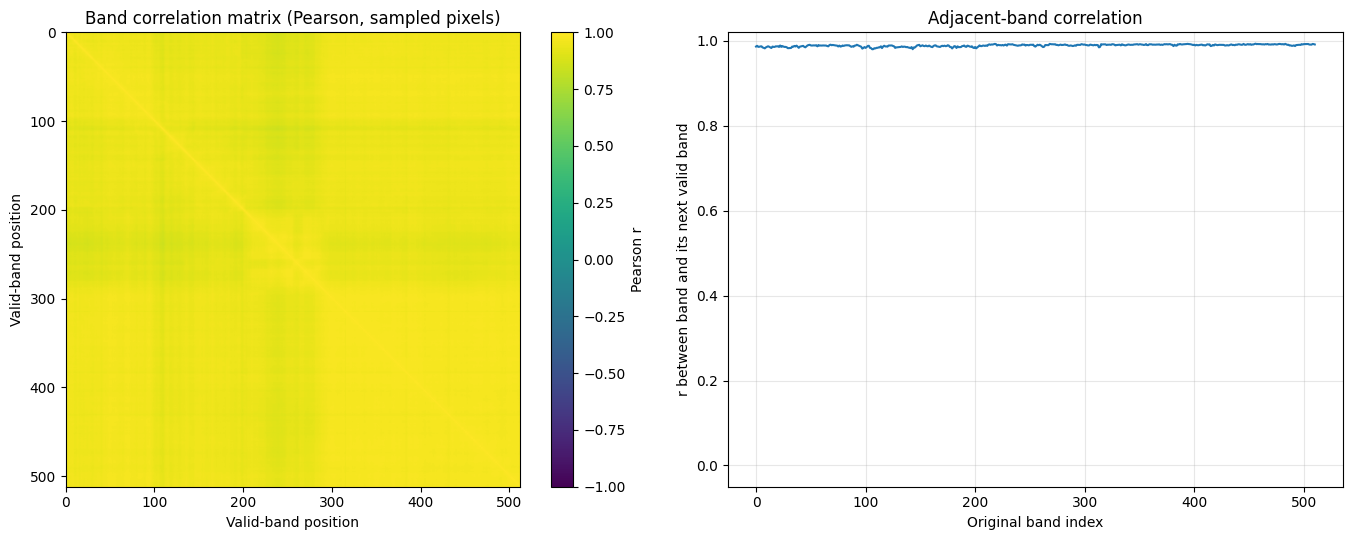

Mean adjacent-band correlation = 0.9891. Values near 1 mean neighbouring bands are nearly redundant.


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
im = ax[0].imshow(R, cmap="viridis", vmin=-1, vmax=1, extent=[0, B_V, B_V, 0])
ax[0].set_title("Band correlation matrix (Pearson, sampled pixels)")
ax[0].set_xlabel("Valid-band position"); ax[0].set_ylabel("Valid-band position"); ax[0].grid(False)
plt.colorbar(im, ax=ax[0], label="Pearson r")
adj = np.array([R[i, i + 1] for i in range(B_V - 1)])
ax[1].plot(VALID_IDX[:-1], adj); ax[1].set_xlabel("Original band index"); ax[1].set_ylabel("r between band and its next valid band")
ax[1].set_title("Adjacent-band correlation"); ax[1].set_ylim(min(0, adj.min()) - 0.05, 1.02)
plt.tight_layout(); savefig("03_band_correlation_heatmap"); plt.show()
print(f"Mean adjacent-band correlation = {adj.mean():.4f}. Values near 1 mean neighbouring bands are nearly redundant.")
pd.DataFrame(R, index=VALID_IDX, columns=VALID_IDX).to_csv(TAB_DIR / "band_correlation_matrix.csv")

### Choosing the number of clusters (diagnostics only)

The user-specified $K$ is the number of **selected bands**, which equals the number of **clusters** in both models (one representative per cluster). Nothing tells us a priori that a given $K$ is "optimal", so we compute *diagnostics* — these inform, but do not replace, the experimental design (fixed $K$ list):

* **Elbow (K-means):** the objective $J(K)=\sum_{k=1}^{K}\sum_{b\in C_k}\lVert z_b-\mu_k\rVert^2$ always decreases with $K$; look for a bend. Limitation: often no clear bend.
* **Silhouette:** $s(b)=\frac{c(b)-a(b)}{\max(a(b),c(b))}$ with $a$ = mean distance to the other members of its own cluster and $c$ = mean distance to the nearest other cluster; average over bands. It is valid here because we use Euclidean distance on $z$. Limitation: favours compact spherical clusters; only ~$B_v$ points are clustered, so values are noisy.
* **Stability:** adjusted Rand index (ARI) between K-means partitions from different seeds (1 = identical). Limitation: stable ≠ meaningful.
* **Hierarchical:** silhouette of the dendrogram cut at each $K$, and the cophenetic correlation of the dendrogram.

## Section 9 — Model A: K-means-based band clustering

**What:** group the $B_v$ bands into $K$ clusters with K-means.
**Why:** bands in the same cluster have similar spatial patterns (high correlation) → one of them can stand for the group.

**Algorithm (Lloyd's), with points $z_b$ = bands:**
1. *Initialise* $K$ centroids (k-means++ : spread-out seeds; `n_init` restarts, best objective kept — this reduces the "sensitivity to initial centres" the review lists as a disadvantage).
2. *Assign:* $c(b)=\arg\min_k \lVert z_b-\mu_k\rVert_2^2$.
3. *Update:* $\mu_k=\frac1{|C_k|}\sum_{b\in C_k}z_b$ (the mean minimises the within-cluster squared error).
4. *Repeat* 2–3 until assignments stop changing or the centroid shift is below `tol` (scikit-learn: `tol=1e-4` relative, `max_iter=300`).

**Objective:** $J=\sum_{k=1}^{K}\sum_{b\in C_k}\lVert z_b-\mu_k\rVert_2^2$ (called *inertia*). Number of **clusters** $K$ = number of **selected bands**.

**Source:** the paper only says group-wise methods cluster bands (K-means is cited as Ahmad et al., 2011); the algorithm above is standard K-means.

## Section 10 — Representative-band selection (shared by both models)

All three rules return an **actual original band**, never a centroid:
* **Nearest-to-centroid (PRIMARY, used for both models):** $r_k=\arg\min_{b\in C_k}\lVert z_b-\mu_k\rVert_2$. With unit-norm $z$ this picks the band most like the cluster's average pattern. For hierarchical clustering the centre is the mean of the cluster's $z$ vectors.
* **Medoid (secondary, hierarchical-friendly):** $r_k=\arg\min_{b\in C_k}\sum_{b'\in C_k}\lVert z_b-z_{b'}\rVert$. A *centroid* is an average that need not be a real band; a *medoid* is the real member with the smallest total distance to the others.
* **Max-entropy (secondary, paper's IE criterion):** $r_k=\arg\max_{b\in C_k}H_b$ with Shannon entropy $H_b=-\sum_j p_{b,j}\log_2 p_{b,j}$ of the band's intensity histogram (`entropy_bins` bins between the band's own min and max, valid pixels). **Not** combined with the centroid distance. Caveat: noisy bands often have high entropy, so this rule can pick noise.

Ties are broken by the lowest band position (deterministic).

In [12]:
# ---------- information entropy per band (used by the entropy-representative rule and by Section 16) ----------
def band_entropy(b_orig, bins):
    v = XB[b_orig][MASK]
    lo, hi = float(v.min()), float(v.max())
    if hi <= lo:
        return 0.0
    h, _ = np.histogram(v, bins=bins, range=(lo, hi))
    p = h[h > 0] / h.sum()
    return float(-(p * np.log2(p)).sum())

ENT = np.array([band_entropy(b, CONFIG["entropy_bins"]) for b in VALID_IDX])     # bits, per valid band
assert np.isfinite(ENT).all() and (ENT >= 0).all()
print(f"Entropy per band ({CONFIG['entropy_bins']} bins, bits): mean {ENT.mean():.3f}, min {ENT.min():.3f}, max {ENT.max():.3f}  "
      f"(upper bound log2({CONFIG['entropy_bins']}) = {math.log2(CONFIG['entropy_bins']):.2f})")

# ---------- representative selection ----------
def cluster_means(Zm, labels, K):
    return np.vstack([Zm[labels == k].mean(axis=0) for k in range(K)])

def select_nearest_centroid(Zm, labels, centers):
    K = centers.shape[0]; reps = np.zeros(K, int); d_all = np.zeros(len(labels))
    for k in range(K):
        mem = np.flatnonzero(labels == k)
        d = np.linalg.norm(Zm[mem] - centers[k], axis=1)
        d_all[mem] = d; reps[k] = mem[np.argmin(d)]
    return reps, d_all

def select_medoid(D, labels, K):
    reps = np.zeros(K, int)
    for k in range(K):
        mem = np.flatnonzero(labels == k)
        reps[k] = mem[np.argmin(D[np.ix_(mem, mem)].sum(axis=1))] if len(mem) > 1 else mem[0]
    return reps

def select_max_entropy(ent, labels, K):
    reps = np.zeros(K, int)
    for k in range(K):
        mem = np.flatnonzero(labels == k)
        reps[k] = mem[np.argmax(ent[mem])]
    return reps

def choose_reps(rep, Zm, labels, centers, D, ent):
    K = centers.shape[0]
    if rep == "centroid": r, d = select_nearest_centroid(Zm, labels, centers)
    elif rep == "medoid": r, d = select_medoid(D, labels, K), None
    elif rep == "entropy": r, d = select_max_entropy(ent, labels, K), None
    else: raise ValueError(rep)
    if d is None: d = np.linalg.norm(Zm - centers[labels], axis=1)
    return r, d

# ---------- Model A ----------
def model_a_kmeans(Zm, K, seed, n_init, rep="centroid"):
    km = KMeans(n_clusters=K, init="k-means++", n_init=n_init, max_iter=300, tol=1e-4, random_state=seed)
    labels = km.fit_predict(Zm)
    assert len(np.unique(labels)) == K, "K-means returned fewer than K non-empty clusters"
    centers = km.cluster_centers_
    reps, dist = choose_reps(rep, Zm, labels, centers, D_EUC if rep == "medoid" else None, ENT)
    return dict(labels=labels, centers=centers, reps=reps, dist=dist, inertia=float(km.inertia_), n_iter=int(km.n_iter_))

# quick correctness test of the objective on the real data
_t = model_a_kmeans(Z, min(5, B_V - 1), CONFIG["seed"], 3)
_J = sum(np.sum((Z[_t["labels"] == k] - _t["centers"][k]) ** 2) for k in range(len(_t["centers"])))
assert np.isclose(_J, _t["inertia"], rtol=1e-6), "inertia != objective J"
print(f"K-means self-check OK: objective J = {_J:.5f} equals scikit-learn inertia; converged in {_t['n_iter']} iterations.")

Entropy per band (256 bins, bits): mean 6.538, min 6.154, max 6.920  (upper bound log2(256) = 8.00)
K-means self-check OK: objective J = 18.60313 equals scikit-learn inertia; converged in 11 iterations.


## Section 12 — Model B: Hierarchical (agglomerative) clustering-based band selection

**What:** build a tree of nested band groups bottom-up, then cut it to get $K$ clusters.
**Why:** no centroid initialisation and a deterministic result; the dendrogram shows how bands merge.

**Procedure**
1. Start with each band as its own cluster ($B_v$ clusters).
2. Compute pairwise distances $d_{bb'}=\lVert z_b-z_{b'}\rVert_2=\sqrt{2(1-r_{bb'})}$ (**same** geometry as Model A).
3. Merge the two closest clusters according to the **linkage** rule; update distances.
4. Repeat until one cluster remains → the **dendrogram** (merge heights = dissimilarity at merge).
5. **Cut** the tree so that exactly $K$ clusters remain (`cut_tree(n_clusters=K)`).

**Linkage rules** (distance between clusters $A,B$):
| Linkage | $D(A,B)$ | Character |
|---|---|---|
| single | $\min_{a,b}d(a,b)$ | chaining: long thin clusters |
| complete | $\max_{a,b}d(a,b)$ | compact clusters, sensitive to outliers |
| average | mean of all $d(a,b)$ | compromise |
| **Ward** | merge pair minimising the increase of within-cluster sum of squares $\Delta=\frac{|A||B|}{|A|+|B|}\lVert\mu_A-\mu_B\rVert^2$ | compact, balanced clusters; same objective family as K-means |

**Ward needs Euclidean geometry.** Our distances are Euclidean distances between the vectors $z_b$ (equivalently $\sqrt{2(1-r)}$), so Ward is valid. The other linkages work with any dissimilarity and are only a secondary ablation.

**Ward ≠ WaLuDi/WaLuMI.** The review mentions those methods but gives no formulas; this notebook implements *standard* Ward and labels it as such.

**Representative:** same three rules as Model A (primary = nearest-to-centre, where the centre is the mean of the cluster's $z$ vectors).
**Dendrogram interpretation:** the vertical axis is the merge distance; cutting the tree with a horizontal line at the level that leaves $K$ branches gives the clusters; long vertical lines before a merge mean the merged groups were quite different.
**Cophenetic correlation:** correlation between original distances and the dendrogram's merge heights (closer to 1 = the tree represents the distances faithfully).

In [13]:
def model_b_hierarchical(Zm, K, linkage_method, rep="centroid"):
    d = pdist(Zm, "euclidean")                                    # condensed Euclidean distances
    Lk = sch.linkage(d, method=linkage_method)
    labels = sch.cut_tree(Lk, n_clusters=K).ravel()
    assert len(np.unique(labels)) == K
    centers = cluster_means(Zm, labels, K)
    Dfull = squareform(d) if rep == "medoid" else None
    reps, dist = choose_reps(rep, Zm, labels, centers, Dfull, ENT)
    coph = float(sch.cophenet(Lk, d)[0])
    return dict(labels=labels, centers=centers, reps=reps, dist=dist, linkage=Lk, cophenetic=coph)

_h = model_b_hierarchical(Z, min(5, B_V - 1), CONFIG["primary_linkage"])
assert _h["linkage"].shape == (B_V - 1, 4)
print(f"Hierarchical self-check OK: linkage matrix {_h['linkage'].shape}, cophenetic correlation ({CONFIG['primary_linkage']}) = {_h['cophenetic']:.4f}")

Hierarchical self-check OK: linkage matrix (511, 4), cophenetic correlation (ward) = 0.8032


saved: /kaggle/working/hsi_band_selection_outputs/figures/04_cluster_count_diagnostics.png


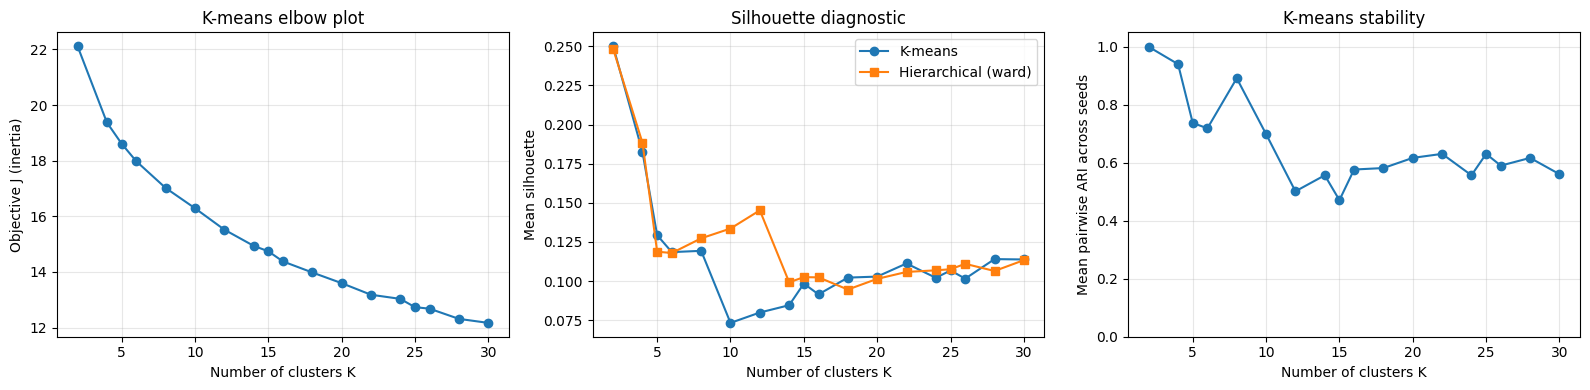

Interpretation: use these as hints only. The comparison itself uses the fixed K list so both models are evaluated at identical K.


In [14]:
# ---------- diagnostics for the cluster count (Section 8 follow-up) ----------
kmax = min(CONFIG["diag_k_max"], B_V - 1)
k_grid = sorted(set(range(2, kmax + 1, CONFIG["diag_k_step"])) | {k for k in CONFIG["K_list"] if 2 <= k <= kmax})
rows = []
Lk_primary = sch.linkage(pdist(Z), method=CONFIG["primary_linkage"])
for k in k_grid:
    labs = [KMeans(n_clusters=k, n_init=CONFIG["diag_n_init"], random_state=s).fit(Z) for s in CONFIG["kmeans_seeds"][:3]]
    lab0 = labs[0].labels_
    ari = np.mean([adjusted_rand_score(labs[i].labels_, labs[j].labels_) for i in range(len(labs)) for j in range(i + 1, len(labs))]) if len(labs) > 1 else np.nan
    hl = sch.cut_tree(Lk_primary, n_clusters=k).ravel()
    rows.append(dict(k=k, kmeans_inertia=min(l.inertia_ for l in labs),
                     kmeans_silhouette=silhouette_score(Z, lab0) if len(np.unique(lab0)) > 1 else np.nan,
                     kmeans_stability_ARI=ari,
                     hier_silhouette=silhouette_score(Z, hl) if len(np.unique(hl)) > 1 else np.nan))
DIAG = pd.DataFrame(rows); DIAG.to_csv(TAB_DIR / "cluster_count_diagnostics.csv", index=False)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(DIAG.k, DIAG.kmeans_inertia, "o-"); ax[0].set_xlabel("Number of clusters K"); ax[0].set_ylabel("Objective J (inertia)"); ax[0].set_title("K-means elbow plot")
ax[1].plot(DIAG.k, DIAG.kmeans_silhouette, "o-", label="K-means"); ax[1].plot(DIAG.k, DIAG.hier_silhouette, "s-", label=f"Hierarchical ({CONFIG['primary_linkage']})")
ax[1].set_xlabel("Number of clusters K"); ax[1].set_ylabel("Mean silhouette"); ax[1].set_title("Silhouette diagnostic"); ax[1].legend()
ax[2].plot(DIAG.k, DIAG.kmeans_stability_ARI, "o-"); ax[2].set_xlabel("Number of clusters K"); ax[2].set_ylabel("Mean pairwise ARI across seeds"); ax[2].set_title("K-means stability"); ax[2].set_ylim(0, 1.05)
plt.tight_layout(); savefig("04_cluster_count_diagnostics"); plt.show()
print("Interpretation: use these as hints only. The comparison itself uses the fixed K list so both models are evaluated at identical K.")

## Section 15 — Common reconstruction baseline (evaluation component, NOT a third model)

Band selection keeps $K$ bands; it does **not** recover the other $B_v-K$. To compute PSNR/SSIM/SAM/MAE we need a full-size cube, so we define **one deterministic baseline** applied identically to both models:

**Linear interpolation along the spectral axis.** With selected coordinates $\lambda_{s_1}<\dots<\lambda_{s_K}$ and an omitted band at $\lambda$ between neighbours $s_l,s_r$:
$$\hat x_\lambda = (1-w)\,x_{s_l}+w\,x_{s_r},\qquad w=\frac{\lambda-\lambda_{s_l}}{\lambda_{s_r}-\lambda_{s_l}} .$$
Outside the selected range the nearest selected band is repeated (constant extrapolation, same as `numpy.interp`).

* Coordinate $\lambda$ = real wavelengths if the dataset provides them, otherwise the original band index (printed above). If only the index is used, interpolation assumes evenly spaced bands.
* Inputs are **only** the selected bands; the omitted original bands are used solely as the *reference* for scoring. No labels, no training.
* **Limitations:** ignores spectral curvature/absorption features, extrapolation at the ends is crude, and it favours *evenly spread* band sets (so metrics measure "coverage along the spectrum" as much as "cluster quality"). Reconstruction scores therefore do **not** show that clustering performs reconstruction.
* **Scope of the scores:** computed over *all valid bands* (selected bands reconstruct exactly, error 0) = "full-cube" scores, **and** over *omitted bands only*. Both are reported; the omitted-only numbers are not diluted by the trivially perfect selected bands.

**Metric definitions** (reference $x$, reconstruction $\hat x$, valid pixel set $\mathcal P$, $n=|\mathcal P|$, fixed range DR):
* $\mathrm{MSE}=\frac1{nB'}\sum_{b,p}(x-\hat x)^2$, $\ \mathrm{PSNR}=10\log_{10}(\mathrm{DR}^2/\mathrm{MSE})$ (dB; $+\infty$ if MSE = 0).
* $\mathrm{SSIM}$: 2-D SSIM per band (window = 7, uniform, `data_range=DR`), averaged over bands.
* $\mathrm{MAE}=\frac1{nB'}\sum|x-\hat x|$ (raw units) and normalised MAE = MAE/DR.
* Relative error per band: $\mathrm{MRE}_b=\frac1{|\mathcal P_b|}\sum_{p\in\mathcal P_b}\frac{|x_{b,p}-\hat x_{b,p}|}{|x_{b,p}|}$ with $\mathcal P_b=\{p:|x_{b,p}|>\varepsilon\}$, $\varepsilon=$ `rel_err_eps_frac`$\times$DR. **Zero-denominator policy:** pixels with $|x|\le\varepsilon$ are excluded; the excluded fraction is recorded. Aggregate = mean over bands.
* $\mathrm{SAM}=\frac1{|\mathcal P'|}\sum_{p}\arccos\!\Big(\mathrm{clip}\big(\tfrac{x_p\cdot\hat x_p}{\lVert x_p\rVert\lVert\hat x_p\rVert},-1,1\big)\Big)$ over valid pixels with non-zero norm (zero-norm pixels excluded, count recorded), spectra taken over all valid bands; reported in radians and degrees; lower is better.

In [15]:
def reconstruction_plan(coord, sel_pos):
    sel_pos = np.sort(np.asarray(sel_pos)); sc = coord[sel_pos]; plan = {}
    for p in range(len(coord)):
        c = coord[p]
        if c <= sc[0]:    plan[p] = (sel_pos[0], sel_pos[0], 0.0)
        elif c >= sc[-1]: plan[p] = (sel_pos[-1], sel_pos[-1], 0.0)
        else:
            r = int(np.searchsorted(sc, c, side="right")); l = r - 1
            plan[p] = (sel_pos[l], sel_pos[r], float((c - sc[l]) / (sc[r] - sc[l])))
    return plan

def reconstruct_band(p, plan):
    l, r, w = plan[p]
    return (1.0 - w) * XB[VALID_IDX[l]] + w * XB[VALID_IDX[r]]

def evaluate_reconstruction(sel_pos):
    """Streaming evaluation (never stores the full reconstructed cube)."""
    sel_pos = np.sort(np.asarray(sel_pos)); sel_set = set(sel_pos.tolist())
    plan = reconstruction_plan(COORD, sel_pos)
    dot = np.zeros((H, W)); nx = np.zeros((H, W)); nr_ = np.zeros((H, W))
    mae_b = np.zeros(B_V); mse_b = np.zeros(B_V); mre_b = np.zeros(B_V); mre_excl = np.zeros(B_V)
    ssim_b = np.ones(B_V); t_rec = 0.0
    for p in range(B_V):
        x = XB[VALID_IDX[p]].astype(np.float64)
        if p in sel_set:
            r = x
        else:
            t0 = time.perf_counter(); r32 = reconstruct_band(p, plan); t_rec += time.perf_counter() - t0
            r = r32.astype(np.float64)
            e = (x - r)[MASK]; xv = x[MASK]; ok = np.abs(xv) > REL_EPS
            mae_b[p] = np.abs(e).mean(); mse_b[p] = (e ** 2).mean()
            mre_b[p] = (np.abs(e)[ok] / np.abs(xv[ok])).mean() if ok.any() else np.nan
            mre_excl[p] = 1.0 - ok.mean()
            if SSIM_OK:
                ssim_b[p] = structural_similarity(x, r, data_range=DR, win_size=WIN)
        dot += x * r; nx += x * x; nr_ += r * r
    omit = np.array([p not in sel_set for p in range(B_V)])
    den = np.sqrt(nx * nr_); ok = MASK & (den > 0)
    ang = np.arccos(np.clip(dot[ok] / den[ok], -1.0, 1.0))
    mse_all = mse_b.mean(); mse_om = mse_b[omit].mean() if omit.any() else 0.0
    psnr = lambda m: float("inf") if m <= 0 else float(10 * np.log10(DR ** 2 / m))
    out = dict(
        PSNR_all=psnr(mse_all), PSNR_omitted=psnr(mse_om),
        SSIM_all=float(ssim_b.mean()) if SSIM_OK else np.nan,
        SSIM_omitted=float(ssim_b[omit].mean()) if (SSIM_OK and omit.any()) else np.nan,
        SAM_rad=float(ang.mean()), SAM_deg=float(np.degrees(ang.mean())), SAM_zero_norm_pixels=int((MASK & ~(den > 0)).sum()),
        MAE_all=float(mae_b.mean()), MAE_omitted=float(mae_b[omit].mean()) if omit.any() else 0.0,
        MAE_norm_omitted=float(mae_b[omit].mean() / DR) if omit.any() else 0.0,
        MRE_all=float(np.nanmean(mre_b)), MRE_omitted=float(np.nanmean(mre_b[omit])) if omit.any() else 0.0,
        MRE_excluded_fraction=float(mre_excl[omit].mean()) if omit.any() else 0.0,
        recon_time_s=t_rec,
    )
    per_band = dict(mae=mae_b, mse=mse_b, mre=mre_b, ssim=ssim_b)
    for k in ("PSNR_all", "SAM_rad", "MAE_all"):
        assert not np.isnan(out[k]), f"NaN in {k}"
    return out, per_band

# self-test: selecting ALL valid bands must give perfect reconstruction
_o, _ = evaluate_reconstruction(np.arange(B_V))
assert _o["MAE_all"] == 0 and _o["SAM_rad"] < 1e-3 and np.isinf(_o["PSNR_all"]), _o
print("Reconstruction self-check OK: keeping all bands gives MAE = 0, PSNR = inf, SAM ~ 0.")

Reconstruction self-check OK: keeping all bands gives MAE = 0, PSNR = inf, SAM ~ 0.


## Section 16 — Evaluation metrics (information, compression, spectral)

**Compression ratio (selected-band storage).** $\mathrm{CR}=\dfrac{\text{Original bits}}{\text{Compressed bits}}$ (higher = more compression), with
Original bits $=H\,W\,B\,b_o$ and Compressed bits $=H\,W\,K\,b_s$; here the stored bit depth $b_s=b_o$ (selected bands are stored as-is), so $\mathrm{CR}=B/K$ — *the same for both methods at a given $K$*. $B$ is the **original total** number of bands. We also report an **effective CR** that adds the overhead of storing the $K$ band indices ($K\lceil\log_2 B\rceil$ bits; no model parameters are needed for decoding by interpolation except the wavelengths, which are treated as dataset metadata). This is *band dropping*, not a general-purpose lossless codec.

**Bits per pixel.** $\mathrm{bpp}=\dfrac{\text{Compressed bits}}{HWB}$ (per original spectral sample) and *bits per spatial pixel* $=\dfrac{\text{Compressed bits}}{HW}$ (per pixel, all kept bands). They differ by the factor $B$.

**Redundancy (lower = less redundant).** $\mathrm{Red}=\frac{2}{K(K-1)}\sum_{i<j}|r_{ij}|$ — mean absolute pairwise Pearson correlation of the *selected* bands (sampled pixels). Low redundancy does **not** guarantee good classification.

**Mean information entropy.** mean over selected bands of $H_b$ (Section 10; `entropy_bins` bins, per-band min–max range, bits). High entropy does not mean a band is useful or noise-free.

**Mean Spectral Divergence (our definition — the review reports values for one method but gives no formula, so numbers are *not* comparable with the paper).** Each band's intensity histogram over a **common fixed range** $[\min,\max]$ with `divergence_bins` bins and additive smoothing $\alpha$ gives a distribution $p_b$. The divergence between bands is the *symmetric* Kullback–Leibler divergence
$$\mathrm{SKL}(b,b')=\sum_j p_{b,j}\ln\frac{p_{b,j}}{p_{b',j}}+\sum_j p_{b',j}\ln\frac{p_{b',j}}{p_{b,j}}\quad[\text{nats}],$$
and $\mathrm{MSD}=\frac{2}{K(K-1)}\sum_{i<j}\mathrm{SKL}$ over the selected bands (higher = more diverse intensity distributions). Being symmetric, direction does not matter. This is **not** the spectral angle and **not** a single KL divergence.

In [16]:
# ---------- histogram distributions and pairwise symmetric KL (computed once) ----------
_nb, _a = CONFIG["divergence_bins"], CONFIG["divergence_smoothing"]
_lo = float(stats.loc[VALID_IDX, "min"].min()); _hi = float(stats.loc[VALID_IDX, "max"].max())
P = np.zeros((B_V, _nb))
for i, b in enumerate(VALID_IDX):
    h, _ = np.histogram(XB[b][MASK], bins=_nb, range=(_lo, _hi))
    P[i] = (h + _a) / (h.sum() + _a * _nb)
LP = np.log(P)
KL = (P * LP).sum(axis=1)[:, None] - P @ LP.T
SKL = KL + KL.T
assert np.isfinite(SKL).all() and np.allclose(SKL, SKL.T) and (np.diag(SKL) < 1e-9).all()

def spectral_metrics(sel_pos):
    sel_pos = np.sort(np.asarray(sel_pos)); K = len(sel_pos)
    iu = np.triu_indices(K, 1)
    return dict(redundancy=float(np.abs(R[np.ix_(sel_pos, sel_pos)])[iu].mean()),
                entropy_mean=float(ENT[sel_pos].mean()),
                MSD=float(SKL[np.ix_(sel_pos, sel_pos)][iu].mean()))

def compression_stats(K):
    orig = H * W * B_TOTAL * ORIG_BITS; comp = H * W * K * ORIG_BITS
    ovh = K * math.ceil(math.log2(B_TOTAL))
    return dict(original_bits=orig, compressed_bits=comp, CR=orig / comp, overhead_bits=ovh,
                CR_effective=orig / (comp + ovh), bpp=comp / (H * W * B_TOTAL), bits_per_spatial_pixel=comp / (H * W),
                original_MiB=orig / 8 / 2**20, selected_MiB=comp / 8 / 2**20)
print(pd.Series(compression_stats(5)).to_string(), "\n(example for K = 5; K is configurable)")

original_bits             5.452595e+07
compressed_bits           5.324800e+05
CR                        1.024000e+02
overhead_bits             4.500000e+01
CR_effective              1.023913e+02
bpp                       1.562500e-01
bits_per_spatial_pixel    8.000000e+01
original_MiB              6.500000e+00
selected_MiB              6.347656e-02 
(example for K = 5; K is configurable)


## Section 17 — Downstream classification evaluation (only if a valid label map exists)

**What:** train one fixed classifier on pixel spectra restricted to the selected bands, using labels **only here**.
**Protocol (identical for every method, every $K$, and the full-band baseline):**
* Pixels: valid, labelled (label ≠ background). If more than `max_labeled_pixels`, a *stratified* random subset is drawn once (fixed seed).
* One stratified split (`train_fraction`, fixed seed) saved and reused → the **same train/test pixels** everywhere. Standardisation is fitted on the training pixels only (no leakage). Classifier: SVM (RBF, fixed C, `gamma='scale'`).
* Metrics: **OA** = fraction correct; **AA** = mean per-class recall (classes present in the test set); **Cohen's κ** = $(p_o-p_e)/(1-p_e)$.
* **Caveat:** neighbouring pixels are spatially correlated, so a random pixel split is optimistic compared with a spatially disjoint split. This applies equally to both methods, so the *comparison* is fair, but absolute accuracies are inflated.

If labels are missing, this section reports **N/A** — nothing is fabricated.

In [17]:
CLS = None
if CONFIG["run_classification"] and LABELS is not None:
    lab_ok = MASK & (LABELS != CONFIG["label_background"])
    pix = np.flatnonzero(lab_ok.ravel()); y_all = LABELS.ravel()[pix]
    cls, cnt = np.unique(y_all, return_counts=True)
    keep_c = cls[cnt >= 4]
    sel_m = np.isin(y_all, keep_c); pix, y_all = pix[sel_m], y_all[sel_m]
    if len(keep_c) < len(cls): print(f"Dropped classes with < 4 labelled pixels: {sorted(set(cls) - set(keep_c))}")
    if len(keep_c) >= 2:
        if len(pix) > CONFIG["max_labeled_pixels"]:
            pix, _, y_all, _ = train_test_split(pix, y_all, train_size=CONFIG["max_labeled_pixels"], stratify=y_all, random_state=CONFIG["seed"])
        tr_pix, te_pix, ytr, yte = train_test_split(pix, y_all, train_size=CONFIG["train_fraction"], stratify=y_all, random_state=CONFIG["seed"])
        assert len(np.intersect1d(tr_pix, te_pix)) == 0, "train/test overlap"
        CLS = dict(tr=tr_pix, te=te_pix, ytr=ytr, yte=yte, classes=np.unique(y_all))
        print(f"Classification enabled: {len(CLS['classes'])} classes | train {len(tr_pix)} | test {len(te_pix)} pixels (no overlap)")
        pd.DataFrame({"class": CLS["classes"], "train": [(ytr == c).sum() for c in CLS["classes"]],
                      "test": [(yte == c).sum() for c in CLS["classes"]]}).to_csv(TAB_DIR / "classification_split_counts.csv", index=False)
    else:
        print("Fewer than 2 usable classes -> classification N/A")
else:
    print("Classification N/A (no labels or disabled).")

def classify(cols_orig):
    if CLS is None:
        return dict(OA=np.nan, AA=np.nan, Kappa=np.nan, classif_time_s=np.nan), None
    t0 = time.perf_counter()
    Xtr = FLAT[np.ix_(cols_orig, CLS["tr"])].T.astype(np.float64); Xte = FLAT[np.ix_(cols_orig, CLS["te"])].T.astype(np.float64)
    sc = StandardScaler().fit(Xtr)                                            # fitted on TRAIN only
    clf = SVC(kernel=CONFIG["svm_kernel"], C=CONFIG["svm_C"], gamma="scale", random_state=CONFIG["seed"]).fit(sc.transform(Xtr), CLS["ytr"])
    pred = clf.predict(sc.transform(Xte))
    cm = confusion_matrix(CLS["yte"], pred, labels=CLS["classes"])
    return dict(OA=float(accuracy_score(CLS["yte"], pred)),
                AA=float(recall_score(CLS["yte"], pred, average="macro", labels=np.unique(CLS["yte"]), zero_division=0)),
                Kappa=float(cohen_kappa_score(CLS["yte"], pred)), classif_time_s=time.perf_counter() - t0), cm

BASELINE = None
if CLS is not None:
    BASELINE, CM_BASE = classify(VALID_IDX)
    BASELINE.update(n_bands=B_V)
    print("Full-band baseline (all valid bands):", {k: round(v, 4) for k, v in BASELINE.items()})
    (TAB_DIR / "full_band_baseline.json").write_text(json.dumps(BASELINE, indent=2))

Classification N/A (no labels or disabled).


## Section 18 — Runtime and memory protocol (identical for both models)

* **Selection time** = wall-clock of the *complete* selection pipeline from the shared feature matrix $Z$ to the $K$ representative indices: K-means = fit + representative; hierarchical = pairwise distances + linkage + cut + representative. (Feature-matrix construction is shared and excluded for both.)
* **Peak memory** = `tracemalloc` peak of a *second, separate* run of the same pipeline. Limitation: it tracks Python/NumPy allocations only; native allocations inside compiled libraries may be under-reported.
* **Reconstruction time** = time spent interpolating omitted bands (excluding metric computation). **Classification time** is reported separately.
* **Model parameters:** clustering is non-parametric → "trainable parameters: N/A". Instead we report the **stored model state on disk** (`.npz`): K-means = centroids + labels + indices; hierarchical = linkage matrix + labels + indices; and a *minimal* state (labels + indices only). Also the size of the selected data.
* Hardware/software are recorded in the export section.

In [18]:
def measure(fn):
    t0 = time.perf_counter(); out = fn(); t = time.perf_counter() - t0
    peak = np.nan
    if CONFIG["measure_memory"]:
        tracemalloc.start(); fn(); _, pk = tracemalloc.get_traced_memory(); tracemalloc.stop(); peak = pk / 2**20
    return out, t, peak

def resolve_K_list():
    ks = ([max(2, int(round(p / 100 * B_TOTAL))) for p in CONFIG["retention_percent"]]
          if CONFIG["retention_percent"] else list(CONFIG["K_list"]))
    ok = sorted({k for k in ks if 2 <= k < B_V}); dropped = sorted(set(ks) - set(ok))
    if dropped: print(f"Dropped invalid K values (need 2 <= K < B_v = {B_V}): {dropped}")
    if not ok:
        ok = sorted({max(2, int(round(p / 100 * B_TOTAL))) for p in (5, 10, 15, 20, 25)} & set(range(2, B_V)))
        print("No valid K in the list -> fell back to 5/10/15/20/25 % of B:", ok)
    assert ok, "no valid K could be formed for this dataset"
    return ok

K_LIST = resolve_K_list()
print("K values (same for both models):", K_LIST, "| retention %:", [round(100 * k / B_TOTAL, 1) for k in K_LIST])

DATA_FP = hashlib.md5(f"{IMG_PATH}|{XB.shape}|{ORIG_DTYPE}|{float(XB.sum(dtype=np.float64)):.6g}".encode()).hexdigest()[:8]
CFG_KEYS = ["seed", "n_sample_pixels", "kmeans_n_init", "entropy_bins", "divergence_bins", "divergence_smoothing", "rel_err_eps_frac",
            "compute_ssim", "train_fraction", "max_labeled_pixels", "svm_C", "svm_kernel", "const_std_tol", "drop_noisy_bands", "label_background"]
CFG_HASH = hashlib.md5(json.dumps({k: CONFIG[k] for k in CFG_KEYS}, sort_keys=True, default=str).encode()).hexdigest()[:8]
RUN_CACHE = CACHE_DIR / f"{DATA_FP}_{CFG_HASH}"; RUN_CACHE.mkdir(exist_ok=True)
print("cache folder:", RUN_CACHE.name)

def run_one(family, K, seed=None, rep="centroid", linkage=None):
    tag = f"{family}_{rep}_{linkage or 'na'}_K{K}_s{seed if seed is not None else 'det'}"
    jf = RUN_CACHE / f"{tag}.json"
    if CONFIG["use_cache"] and jf.exists():
        return json.loads(jf.read_text())
    if family == "kmeans":
        fn = lambda: model_a_kmeans(Z, K, seed, CONFIG["kmeans_n_init"], rep)
    else:
        fn = lambda: model_b_hierarchical(Z, K, linkage, rep)
    res, t_sel, peak = measure(fn)
    sel_pos = np.sort(res["reps"])
    # ---- validation ----
    assert len(sel_pos) == K and len(set(sel_pos.tolist())) == K, "duplicate / wrong number of selected bands"
    assert sel_pos.min() >= 0 and sel_pos.max() < B_V
    sel_orig = VALID_IDX[sel_pos]
    assert len(set(sel_orig.tolist())) == K and not (set(sel_orig.tolist()) & set(CONST_BANDS.tolist()))
    # ---- metrics ----
    rec, perband = evaluate_reconstruction(sel_pos)
    spec = spectral_metrics(sel_pos); comp = compression_stats(K)
    cls_res, cm = classify(sel_orig)
    # ---- model size on disk ----
    state = dict(labels=res["labels"], selected=sel_orig)
    full_state = dict(state, **({"centers": res["centers"]} if family == "kmeans" else {"linkage": res["linkage"]}))
    tmp = RUN_CACHE / "_tmp.npz"; np.savez(tmp, **full_state); size_full = tmp.stat().st_size
    np.savez(tmp, **state); size_min = tmp.stat().st_size; tmp.unlink()
    row = dict(tag=tag, family=family, rep=rep, linkage=linkage or "N/A", K=K, seed=seed if seed is not None else -1,
               n_original_bands=B_TOTAL, n_valid_bands=B_V, retention_pct=100 * K / B_TOTAL,
               selected_0based=json.dumps(sel_orig.tolist()), selected_1based=json.dumps((sel_orig + 1).tolist()),
               inertia=res.get("inertia", np.nan), cophenetic=res.get("cophenetic", np.nan),
               selection_time_s=t_sel, peak_mem_MiB=peak, model_state_bytes=size_full, model_minimal_bytes=size_min,
               selected_data_bytes=comp["compressed_bits"] / 8, trainable_params="N/A (non-parametric)")
    row.update(comp); row.update(spec); row.update(rec); row.update(cls_res)
    np.savez(SEL_DIR / f"{tag}.npz", labels=res["labels"], reps_valid_pos=sel_pos, selected_orig=sel_orig,
             rep_per_cluster=res["reps"], dist_to_centroid=res["dist"], centers=res["centers"],
             linkage=res.get("linkage", np.zeros((0, 4))), cm=cm if cm is not None else np.zeros((0, 0)), valid_idx=VALID_IDX,
             **{f"pb_{k}": v for k, v in perband.items()})
    jf.write_text(json.dumps(row, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
    return row

def load_sel(tag):
    return np.load(SEL_DIR / f"{tag}.npz")
print("experiment runner ready.")

K values (same for both models): [5, 10, 15, 20, 25] | retention %: [1.0, 2.0, 2.9, 3.9, 4.9]
cache folder: f774a81f_b17c50c5
experiment runner ready.


## Section 19 — Run the fair comparison

For every $K$ in the list, **both models are run on the same $Z$**, with the same primary representative rule (nearest-to-centroid):
* **K-means:** repeated with several random seeds → mean ± std (K-means is stochastic).
* **Hierarchical (Ward):** deterministic → one run, no std.

*Secondary experiments* (clearly separate, labelled): medoid and max-entropy representatives for both families, and average/complete/single linkage for the hierarchical family. They are **not** replacements for the primary comparison.

Each run is checkpointed in the cache folder; if the session restarts just re-run this cell. **Expected time:** depends on image size (SSIM and the per-band reconstruction dominate).

In [19]:
t_all = time.time(); records = []
def log(r): print(f"  {r['tag']:<42} sel {r['selection_time_s']:.3f}s | PSNR_all {r['PSNR_all']:.2f} | SAM {r['SAM_deg']:.3f} deg | OA {r['OA'] if r['OA']==r['OA'] else float('nan'):.4f}")

print("== PRIMARY EXPERIMENTS ==")
for K in K_LIST:
    for s in CONFIG["kmeans_seeds"]:
        r = run_one("kmeans", K, seed=s, rep="centroid"); records.append(r); log(r)
    r = run_one("hier", K, rep="centroid", linkage=CONFIG["primary_linkage"]); records.append(r); log(r)

if CONFIG["run_secondary"]:
    print("== SECONDARY EXPERIMENTS (representative-rule variants, linkage ablation) ==")
    sec_seeds = CONFIG["kmeans_seeds"][:CONFIG["secondary_n_seeds"]]
    for K in K_LIST:
        for rep in ("medoid", "entropy"):
            for s in sec_seeds:
                r = run_one("kmeans", K, seed=s, rep=rep); records.append(r)
            r = run_one("hier", K, rep=rep, linkage=CONFIG["primary_linkage"]); records.append(r)
        for lk in CONFIG["compare_linkages"]:
            r = run_one("hier", K, rep="centroid", linkage=lk); records.append(r)
    print(f"secondary runs done.")

RES = pd.DataFrame(records).drop_duplicates("tag").reset_index(drop=True)
RES.to_csv(TAB_DIR / "all_runs.csv", index=False)
RES[["tag", "family", "rep", "linkage", "K", "seed", "n_original_bands", "selected_0based", "selected_1based"]].to_csv(TAB_DIR / "selected_band_indices_all_runs.csv", index=False)
print(f"\n{len(RES)} runs saved -> {TAB_DIR/'all_runs.csv'} | elapsed {time.time()-t_all:.1f}s")

== PRIMARY EXPERIMENTS ==
  kmeans_centroid_na_K5_s0                   sel 1.423s | PSNR_all 28.08 | SAM 4.034 deg | OA nan
  kmeans_centroid_na_K5_s1                   sel 1.454s | PSNR_all 28.07 | SAM 4.037 deg | OA nan
  kmeans_centroid_na_K5_s2                   sel 1.333s | PSNR_all 28.08 | SAM 4.048 deg | OA nan
  kmeans_centroid_na_K5_s3                   sel 1.422s | PSNR_all 28.08 | SAM 4.034 deg | OA nan
  kmeans_centroid_na_K5_s4                   sel 1.424s | PSNR_all 28.08 | SAM 4.048 deg | OA nan
  hier_centroid_ward_K5_sdet                 sel 0.514s | PSNR_all 28.04 | SAM 4.033 deg | OA nan
  kmeans_centroid_na_K10_s0                  sel 1.662s | PSNR_all 28.61 | SAM 3.877 deg | OA nan
  kmeans_centroid_na_K10_s1                  sel 1.792s | PSNR_all 28.68 | SAM 3.832 deg | OA nan
  kmeans_centroid_na_K10_s2                  sel 1.738s | PSNR_all 28.69 | SAM 3.797 deg | OA nan
  kmeans_centroid_na_K10_s3                  sel 1.842s | PSNR_all 28.75 | SAM 3.828 deg | O

## Sections 11 & 14 — Outputs and visualisations for each model

**What:** for a chosen reference $K$ (`K_REF`, default = median of the list) show cluster assignments, cluster sizes, representative bands, the dendrogram, and the selected-band images.
**K-means reference run** = the seed with the lowest objective $J$ at that $K$.
**Expected output:** (K-means) cluster membership along the spectrum, a 2-D *visualisation* of the band feature space, cluster sizes, representatives on the mean spectrum; (hierarchical) the dendrogram with representatives in red, the same plots; then the selected-band images.
**About the 2-D scatter:** it uses an SVD projection **only to draw** the points; the clustering itself uses the full $z$ vectors. It is not a feature-extraction step.

Reference K = 15. K-means reference seed = 2 (lowest J = 14.65844).
saved: /kaggle/working/hsi_band_selection_outputs/figures/05_kmeans_clusters.png


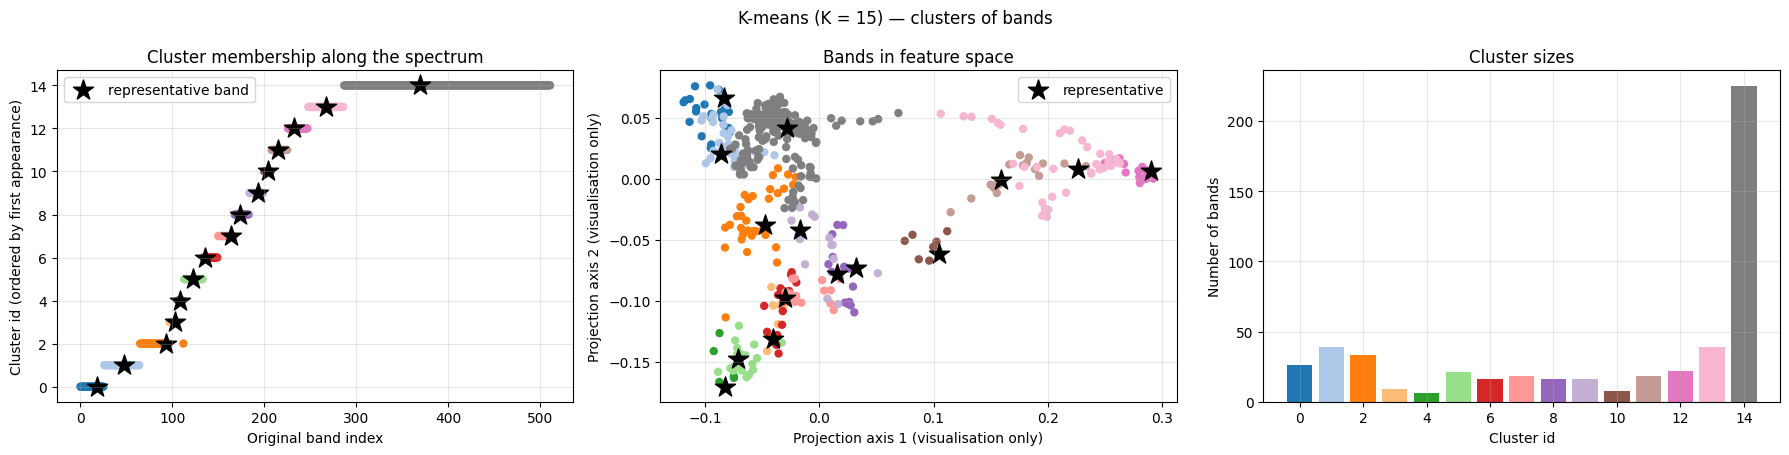

saved: /kaggle/working/hsi_band_selection_outputs/figures/08_hierarchical_clusters.png


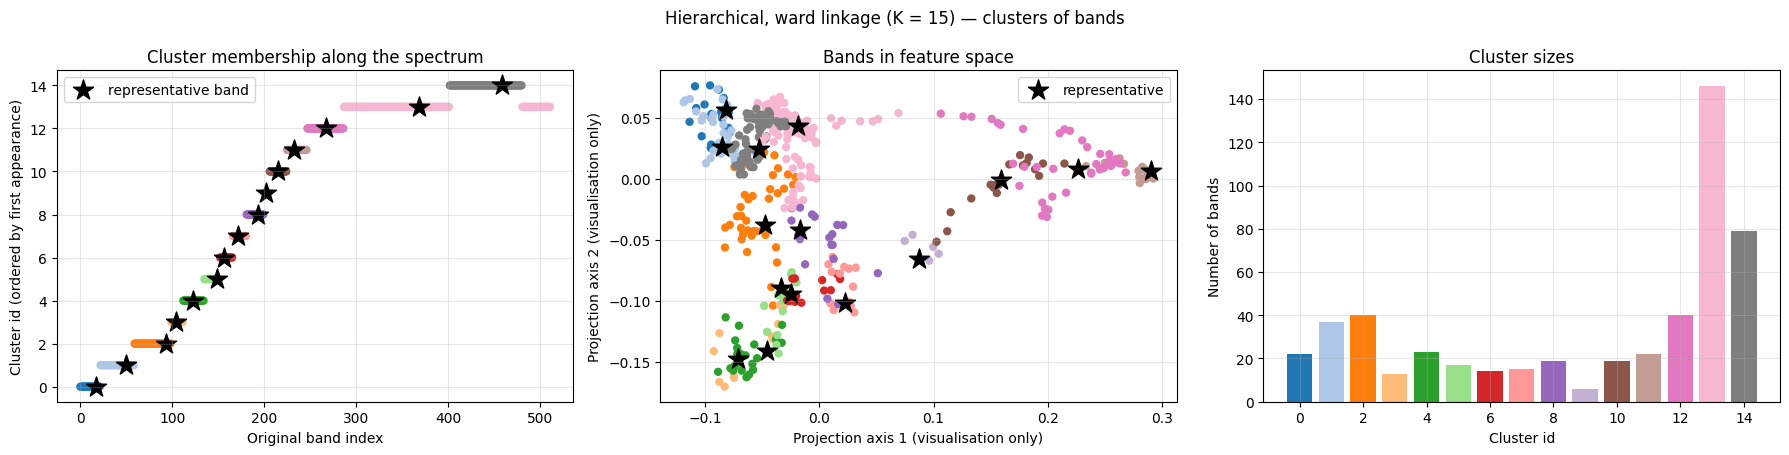

K-means cluster sizes: [225, 39, 39, 33, 26, 22, 21, 18, 18, 16, 16, 16, 9, 8, 6]
Hierarchical cluster sizes: [146, 79, 40, 40, 37, 23, 22, 22, 19, 19, 17, 15, 14, 13, 6]
Interpretation: clusters of contiguous bands indicate smooth spectral redundancy; very unequal sizes mean some clusters are tiny (often noisy/outlier bands).
saved: /kaggle/working/hsi_band_selection_outputs/figures/06_representative_bands_on_spectrum.png


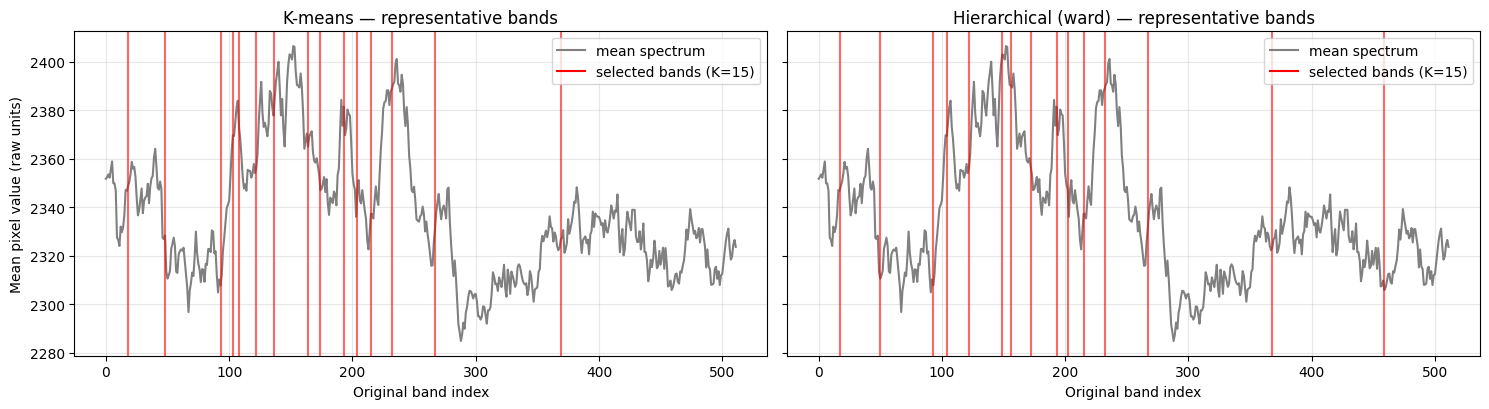

In [20]:
K_REF = K_LIST[len(K_LIST) // 2]
prim = RES[(RES.rep == "centroid") & (((RES.family == "kmeans")) | ((RES.family == "hier") & (RES.linkage == CONFIG["primary_linkage"])))]
km_ref_row = prim[(prim.family == "kmeans") & (prim.K == K_REF)].sort_values("inertia").iloc[0]
hc_ref_row = prim[(prim.family == "hier") & (prim.K == K_REF)].iloc[0]
KM, HC = load_sel(km_ref_row.tag), load_sel(hc_ref_row.tag)
print(f"Reference K = {K_REF}. K-means reference seed = {int(km_ref_row.seed)} (lowest J = {km_ref_row.inertia:.5f}).")

def relabel_first_appearance(lab):
    order = {}; out = np.zeros_like(lab)
    for i, l in enumerate(lab): out[i] = order.setdefault(l, len(order))
    return out

# 2-D visualisation coordinates (drawing only)
U, S, _ = np.linalg.svd(Z - Z.mean(axis=0), full_matrices=False); XY = U[:, :2] * S[:2]
cmap = plt.get_cmap("tab20")

def cluster_figure(name, res, title):
    lab = relabel_first_appearance(res["labels"]); reps = res["reps_valid_pos"]
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
    ax[0].scatter(VALID_IDX, lab, c=[cmap(l % 20) for l in lab], s=25)
    ax[0].scatter(VALID_IDX[reps], lab[reps], marker="*", s=230, c="k", label="representative band"); ax[0].legend()
    ax[0].set_xlabel("Original band index"); ax[0].set_ylabel("Cluster id (ordered by first appearance)"); ax[0].set_title("Cluster membership along the spectrum")
    ax[1].scatter(XY[:, 0], XY[:, 1], c=[cmap(l % 20) for l in lab], s=25)
    ax[1].scatter(XY[reps, 0], XY[reps, 1], marker="*", s=230, c="k", label="representative"); ax[1].legend()
    ax[1].set_xlabel("Projection axis 1 (visualisation only)"); ax[1].set_ylabel("Projection axis 2 (visualisation only)"); ax[1].set_title("Bands in feature space")
    sizes = np.bincount(lab); ax[2].bar(np.arange(len(sizes)), sizes, color=[cmap(i % 20) for i in range(len(sizes))])
    ax[2].set_xlabel("Cluster id"); ax[2].set_ylabel("Number of bands"); ax[2].set_title("Cluster sizes")
    plt.suptitle(title); plt.tight_layout(); savefig(name); plt.show()
    return sizes

sz_km = cluster_figure("05_kmeans_clusters", KM, f"K-means (K = {K_REF}) — clusters of bands")
sz_hc = cluster_figure("08_hierarchical_clusters", HC, f"Hierarchical, {CONFIG['primary_linkage']} linkage (K = {K_REF}) — clusters of bands")
print("K-means cluster sizes:", sorted(sz_km.tolist(), reverse=True)); print("Hierarchical cluster sizes:", sorted(sz_hc.tolist(), reverse=True))
print("Interpretation: clusters of contiguous bands indicate smooth spectral redundancy; very unequal sizes mean some clusters are tiny (often noisy/outlier bands).")

# representative bands on the mean spectrum
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
for a, res, t in zip(ax, (KM, HC), ("K-means", f"Hierarchical ({CONFIG['primary_linkage']})")):
    a.plot(xl, mean_sp, color="gray", label="mean spectrum")
    for p in res["reps_valid_pos"]: a.axvline(xl[p], color="r", alpha=0.6)
    a.plot([], [], color="r", label=f"selected bands (K={K_REF})"); a.set_title(t + " — representative bands"); a.set_xlabel(xlabel); a.legend()
ax[0].set_ylabel("Mean pixel value (raw units)")
plt.tight_layout(); savefig("06_representative_bands_on_spectrum"); plt.show()

saved: /kaggle/working/hsi_band_selection_outputs/figures/07_hierarchical_dendrogram.png


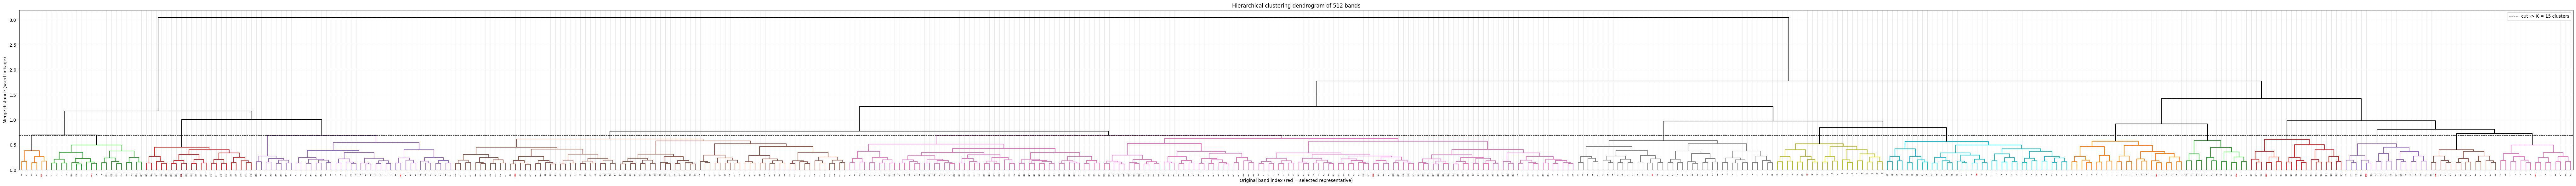

Reading the plot: bands joined low in the tree are highly similar; the dashed line cuts the tree into the K groups; red labels are the selected bands.


In [21]:
# ---------- dendrogram (Model B). All bands are used in clustering; the full tree is drawn ----------
Lk = HC["linkage"]
thr = 0.5 * (Lk[B_V - K_REF - 1, 2] + Lk[B_V - K_REF, 2])          # horizontal cut that leaves K_REF clusters
fig, ax = plt.subplots(figsize=(max(14, B_V * 0.16), 6))
dn = sch.dendrogram(Lk, labels=[str(b) for b in VALID_IDX], color_threshold=thr, leaf_rotation=90,
                    leaf_font_size=max(4, min(9, 900 // B_V)), ax=ax, above_threshold_color="black")
ax.axhline(thr, color="k", ls="--", lw=1, label=f"cut -> K = {K_REF} clusters"); ax.legend()
sel_set = set(VALID_IDX[HC["reps_valid_pos"]].tolist())
for lbl in ax.get_xmajorticklabels():
    if int(lbl.get_text()) in sel_set: lbl.set_color("red"); lbl.set_fontweight("bold")
ax.set_xlabel("Original band index (red = selected representative)"); ax.set_ylabel(f"Merge distance ({CONFIG['primary_linkage']} linkage)")
ax.set_title(f"Hierarchical clustering dendrogram of {B_V} bands")
plt.tight_layout(); savefig("07_hierarchical_dendrogram"); plt.show()
print("Reading the plot: bands joined low in the tree are highly similar; the dashed line cuts the tree into the K groups; red labels are the selected bands.")

saved: /kaggle/working/hsi_band_selection_outputs/figures/09_selected_band_images.png


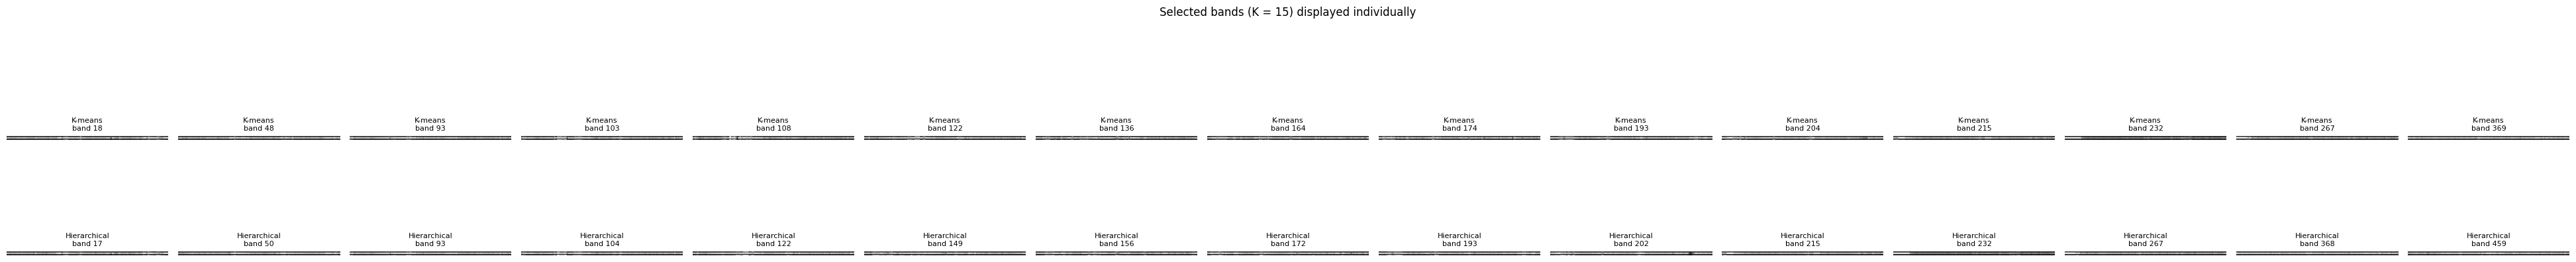

saved: /kaggle/working/hsi_band_selection_outputs/figures/10_selected_vs_unselected_bands.png


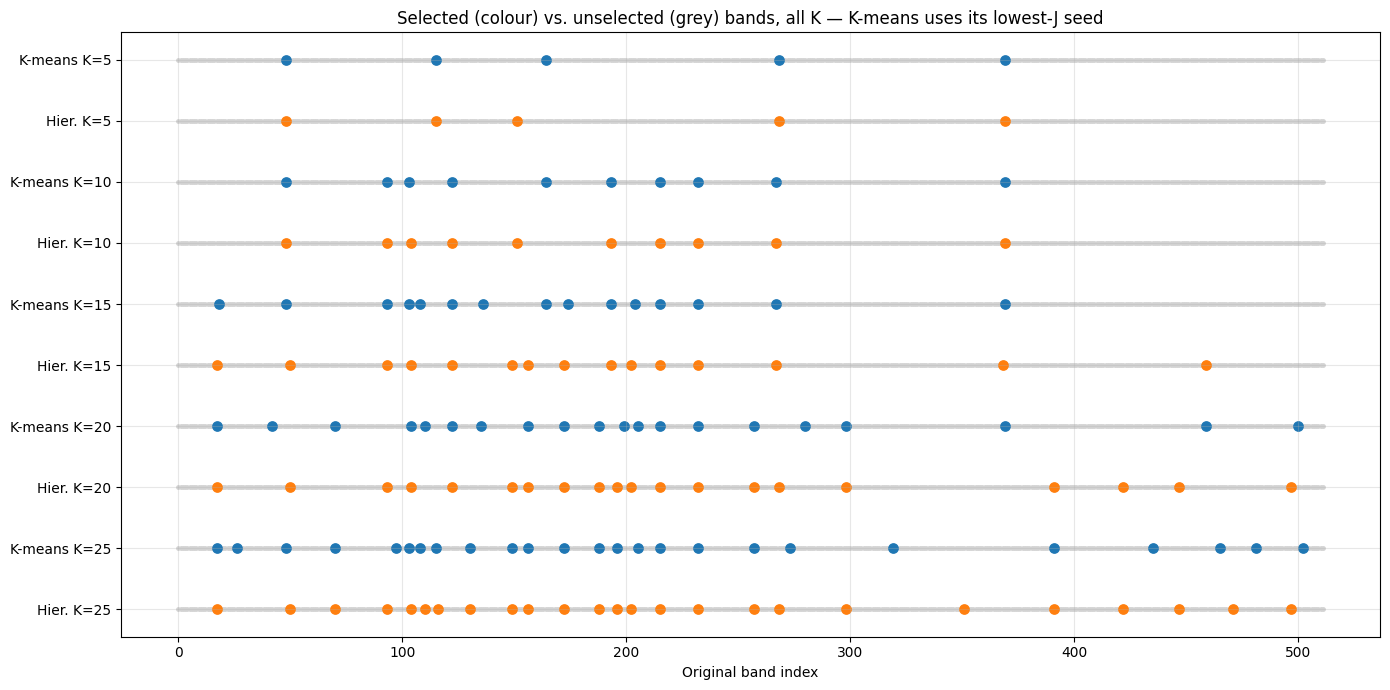

Selected original band indices (0-based):
  K=  5 | K-means: [48, 115, 164, 268, 369]
        | Hier.  : [48, 115, 151, 268, 369]
        | shared bands: [48, 115, 268, 369]
  K= 10 | K-means: [48, 93, 103, 122, 164, 193, 215, 232, 267, 369]
        | Hier.  : [48, 93, 104, 122, 151, 193, 215, 232, 267, 369]
        | shared bands: [48, 93, 122, 193, 215, 232, 267, 369]
  K= 15 | K-means: [18, 48, 93, 103, 108, 122, 136, 164, 174, 193, 204, 215, 232, 267, 369]
        | Hier.  : [17, 50, 93, 104, 122, 149, 156, 172, 193, 202, 215, 232, 267, 368, 459]
        | shared bands: [93, 122, 193, 215, 232, 267]
  K= 20 | K-means: [17, 42, 70, 104, 110, 122, 135, 156, 172, 188, 199, 205, 215, 232, 257, 280, 298, 369, 459, 500]
        | Hier.  : [17, 50, 93, 104, 122, 149, 156, 172, 188, 196, 202, 215, 232, 257, 268, 298, 391, 422, 447, 497]
        | shared bands: [17, 104, 122, 156, 172, 188, 215, 232, 257, 298]
  K= 25 | K-means: [17, 26, 48, 70, 97, 103, 108, 115, 130, 149, 156, 172, 188, 1

In [22]:
# ---------- selected-band images, selected vs unselected distribution, comparison of indices ----------
fig, ax = plt.subplots(2, K_REF, figsize=(2.6 * K_REF, 5.6), squeeze=False)
for r_i, (res, t) in enumerate(((KM, "K-means"), (HC, "Hierarchical"))):
    for j, p in enumerate(np.sort(res["reps_valid_pos"])):
        ax[r_i, j].imshow(stretch(XB[VALID_IDX[p]]), cmap="gray"); ax[r_i, j].set_title(f"{t}\nband {VALID_IDX[p]}", fontsize=8); ax[r_i, j].axis("off")
plt.suptitle(f"Selected bands (K = {K_REF}) displayed individually"); plt.tight_layout(); savefig("09_selected_band_images"); plt.show()

fig, ax = plt.subplots(figsize=(14, 0.5 * len(K_LIST) * 2 + 2))
ypos = 0; yt, yl = [], []
for K in K_LIST:
    kr = prim[(prim.family == "kmeans") & (prim.K == K)].sort_values("inertia").iloc[0]; hr = prim[(prim.family == "hier") & (prim.K == K)].iloc[0]
    for name, r, c in (("K-means", kr, "tab:blue"), ("Hier.", hr, "tab:orange")):
        sel = json.loads(r.selected_0based); ax.scatter(VALID_IDX, np.full(B_V, ypos), s=6, color="lightgray")
        ax.scatter(sel, np.full(len(sel), ypos), s=45, color=c, marker="o"); yt.append(ypos); yl.append(f"{name} K={K}"); ypos += 1
ax.set_yticks(yt); ax.set_yticklabels(yl); ax.set_xlabel("Original band index"); ax.set_title("Selected (colour) vs. unselected (grey) bands, all K — K-means uses its lowest-J seed")
ax.invert_yaxis(); plt.tight_layout(); savefig("10_selected_vs_unselected_bands"); plt.show()

print("Selected original band indices (0-based):")
for K in K_LIST:
    kr = prim[(prim.family == "kmeans") & (prim.K == K)].sort_values("inertia").iloc[0]; hr = prim[(prim.family == "hier") & (prim.K == K)].iloc[0]
    a, b = json.loads(kr.selected_0based), json.loads(hr.selected_0based)
    print(f"  K={K:>3} | K-means: {a}\n        | Hier.  : {b}\n        | shared bands: {sorted(set(a) & set(b))}")

## Section 15 (continued) — Original vs. reconstructed bands and error maps

**What:** for the reference $K$, compare an omitted band with its interpolation-based reconstruction from each model's selected bands, plus the absolute-error map.
**Why:** shows *where* the baseline fails. Remember: errors reflect the selected band set **plus** the simple interpolation baseline.
**Expected output:** for 2 omitted bands: original, K-means reconstruction, hierarchical reconstruction, and two error maps on a common colour scale.

saved: /kaggle/working/hsi_band_selection_outputs/figures/11_12_reconstruction_and_error_maps.png


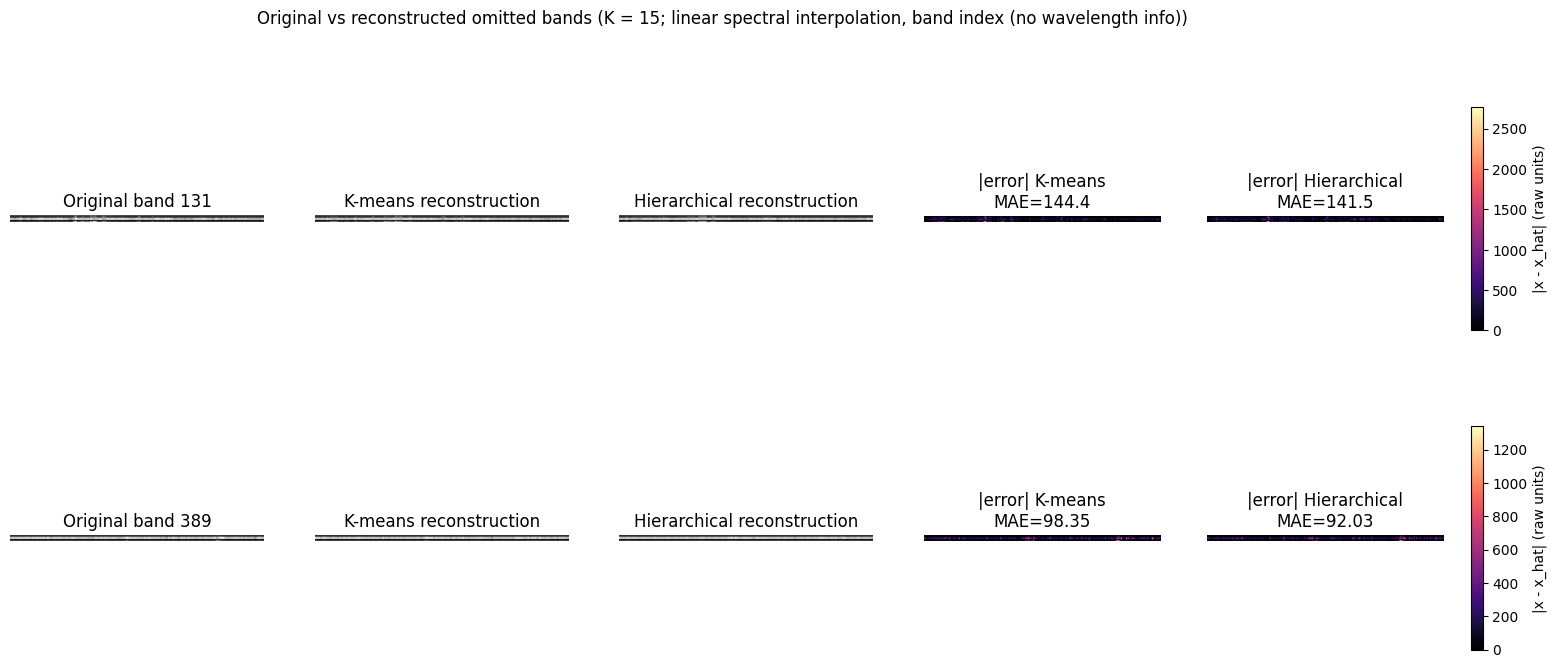

saved: /kaggle/working/hsi_band_selection_outputs/figures/13a_per_band_errors.png


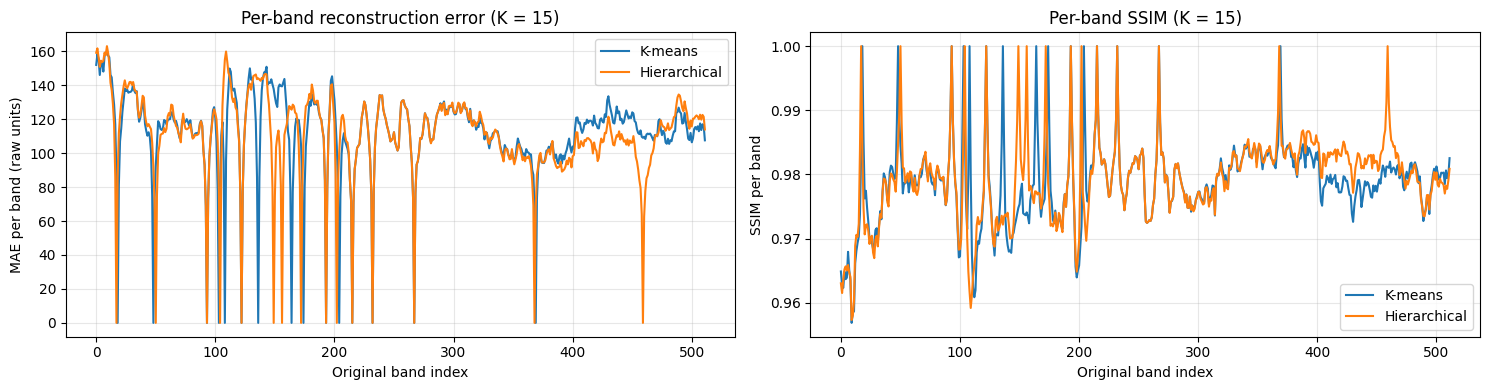

In [23]:
cands = [p for p in range(B_V) if p not in set(KM["reps_valid_pos"]) and p not in set(HC["reps_valid_pos"])]
show = [cands[len(cands) // 4], cands[(3 * len(cands)) // 4]] if len(cands) >= 4 else cands[:2]
plans = {"K-means": reconstruction_plan(COORD, KM["reps_valid_pos"]), "Hierarchical": reconstruction_plan(COORD, HC["reps_valid_pos"])}
fig, ax = plt.subplots(len(show), 5, figsize=(19, 3.8 * len(show)), squeeze=False)
for i, p in enumerate(show):
    x = XB[VALID_IDX[p]]; recs = {k: reconstruct_band(p, pl) for k, pl in plans.items()}
    err = {k: np.abs(x - v) * MASK for k, v in recs.items()}; emax = max(e.max() for e in err.values()) or 1
    vmin, vmax = np.percentile(x[MASK], [2, 98])
    ax[i, 0].imshow(x, cmap="gray", vmin=vmin, vmax=vmax); ax[i, 0].set_title(f"Original band {VALID_IDX[p]}")
    for j, k in enumerate(("K-means", "Hierarchical")):
        ax[i, 1 + j].imshow(recs[k], cmap="gray", vmin=vmin, vmax=vmax); ax[i, 1 + j].set_title(f"{k} reconstruction")
        im = ax[i, 3 + j].imshow(err[k], cmap="magma", vmin=0, vmax=emax); ax[i, 3 + j].set_title(f"|error| {k}\nMAE={err[k][MASK].mean():.4g}")
    for a in ax[i]: a.axis("off")
    plt.colorbar(im, ax=ax[i, 3:], fraction=0.02, label="|x - x_hat| (raw units)")
plt.suptitle(f"Original vs reconstructed omitted bands (K = {K_REF}; linear spectral interpolation, {COORD_KIND})")
savefig("11_12_reconstruction_and_error_maps"); plt.show()

# per-band errors along the spectrum
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for res, lab_ in ((KM, "K-means"), (HC, "Hierarchical")):
    ax[0].plot(VALID_IDX, res["pb_mae"], label=lab_); ax[1].plot(VALID_IDX, res["pb_ssim"], label=lab_)
ax[0].set_xlabel("Original band index"); ax[0].set_ylabel("MAE per band (raw units)"); ax[0].set_title(f"Per-band reconstruction error (K = {K_REF})"); ax[0].legend()
ax[1].set_xlabel("Original band index"); ax[1].set_ylabel("SSIM per band"); ax[1].set_title(f"Per-band SSIM (K = {K_REF})"); ax[1].legend()
plt.tight_layout(); savefig("13a_per_band_errors"); plt.show()
pd.DataFrame({"band": VALID_IDX, "kmeans_mae": KM["pb_mae"], "hier_mae": HC["pb_mae"], "kmeans_mre": KM["pb_mre"], "hier_mre": HC["pb_mre"],
              "kmeans_ssim": KM["pb_ssim"], "hier_ssim": HC["pb_ssim"]}).to_csv(TAB_DIR / f"per_band_errors_K{K_REF}.csv", index=False)

## Section 19 (continued) — Results comparison

Rows below are **measured values**. K-means entries are `mean ± std` over its seeds (n shown); hierarchical is deterministic (no std). "N/A" = not computable (e.g. no labels). *Scope tags:* metrics marked **[recon]** are computed on the interpolation-reconstructed cube (all valid bands = "full-cube"); **[selected]** metrics are computed directly on the selected bands; **[labels]** need ground truth.

In [24]:
METRICS = [  # (display name, column, scope, higher_is_better, format)
    ("Number of selected bands", "K", "[selected]", None, "{:.0f}"),
    ("Compression ratio (CR = orig/comp)", "CR", "[selected]", True, "{:.3f}"),
    ("Effective CR incl. index overhead", "CR_effective", "[selected]", True, "{:.3f}"),
    ("Bits per original sample (bpp)", "bpp", "[selected]", None, "{:.4f}"),
    ("Bits per spatial pixel", "bits_per_spatial_pixel", "[selected]", None, "{:.1f}"),
    ("PSNR dB, full cube", "PSNR_all", "[recon]", True, "{:.3f}"),
    ("PSNR dB, omitted bands only", "PSNR_omitted", "[recon]", True, "{:.3f}"),
    ("SSIM, full cube", "SSIM_all", "[recon]", True, "{:.4f}"),
    ("SSIM, omitted bands only", "SSIM_omitted", "[recon]", True, "{:.4f}"),
    ("SAM (degrees)", "SAM_deg", "[recon]", False, "{:.4f}"),
    ("MAE (raw units), omitted bands", "MAE_omitted", "[recon]", False, "{:.4g}"),
    ("MAE (raw units), full cube", "MAE_all", "[recon]", False, "{:.4g}"),
    ("Mean relative error, omitted bands", "MRE_omitted", "[recon]", False, "{:.4g}"),
    ("Spectral redundancy (mean |r|)", "redundancy", "[selected]", False, "{:.4f}"),
    ("Mean information entropy (bits)", "entropy_mean", "[selected]", True, "{:.4f}"),
    ("Mean spectral divergence (sym. KL, nats; our definition)", "MSD", "[selected]", True, "{:.4f}"),
    ("Overall accuracy (OA)", "OA", "[labels]", True, "{:.4f}"),
    ("Average accuracy (AA)", "AA", "[labels]", True, "{:.4f}"),
    ("Cohen's kappa", "Kappa", "[labels]", True, "{:.4f}"),
    ("Selection time (s)", "selection_time_s", "[selected]", False, "{:.4f}"),
    ("Reconstruction time (s)", "recon_time_s", "[recon]", False, "{:.4f}"),
    ("Peak memory during selection (MiB, tracemalloc)", "peak_mem_MiB", "[selected]", False, "{:.2f}"),
    ("Stored model state on disk (bytes)", "model_state_bytes", "[selected]", False, "{:.0f}"),
    ("Minimal state: labels+indices (bytes)", "model_minimal_bytes", "[selected]", False, "{:.0f}"),
    ("Selected-data size (bytes)", "selected_data_bytes", "[selected]", False, "{:.0f}"),
]
HIB = {m[1]: m[3] for m in METRICS}

def fmt(v, f):
    return "N/A" if (v is None or (isinstance(v, float) and np.isnan(v))) else ("inf" if np.isinf(v) else f.format(v))

def final_table(K):
    km = prim[(prim.family == "kmeans") & (prim.K == K)]; hc = prim[(prim.family == "hier") & (prim.K == K)]
    rows = []
    for name, col, scope, hib, f in METRICS:
        m, s = km[col].astype(float).mean(), km[col].astype(float).std(ddof=0)
        kcell = fmt(m, f) if len(km) <= 1 or np.isnan(s) or s == 0 else f"{fmt(m, f)} ± {fmt(s, f)}"
        hcell = fmt(float(hc[col].iloc[0]), f)
        rows.append({"Metric": f"{name} {scope}", f"K-means (mean ± std, n={len(km)})": kcell, f"Hierarchical ({CONFIG['primary_linkage']})": hcell})
    return pd.DataFrame(rows)

FINAL = {}
for K in K_LIST:
    FINAL[K] = final_table(K); FINAL[K].to_csv(TAB_DIR / f"final_comparison_K{K}.csv", index=False)
print(f"Comparison table for K = {K_REF} (all K saved as CSV in {TAB_DIR}):\n")
print(FINAL[K_REF].to_string(index=False))
if BASELINE: print("\nFull-band baseline (classification, all", B_V, "valid bands):", {k: round(v, 4) for k, v in BASELINE.items() if k != "n_bands"})

Comparison table for K = 15 (all K saved as CSV in /kaggle/working/hsi_band_selection_outputs/tables):

                                                             Metric K-means (mean ± std, n=5) Hierarchical (ward)
                                Number of selected bands [selected]                        15                  15
                      Compression ratio (CR = orig/comp) [selected]                    34.133              34.133
                       Effective CR incl. index overhead [selected]                    34.130              34.130
                          Bits per original sample (bpp) [selected]                    0.4688              0.4688
                                  Bits per spatial pixel [selected]                     240.0               240.0
                                         PSNR dB, full cube [recon]            29.054 ± 0.082              29.098
                                PSNR dB, omitted bands only [recon]            28.924 ± 0.082     

In [25]:
# aggregated table over all K (primary experiments) + secondary experiments
num_cols = [m[1] for m in METRICS if m[1] != "K"]
agg = RES.groupby(["family", "rep", "linkage", "K"])[num_cols].agg(["mean", "std"]); agg["n_runs"] = RES.groupby(["family", "rep", "linkage", "K"]).size()
agg.to_csv(TAB_DIR / "aggregated_results_all_experiments.csv")
print("Aggregated table (primary + secondary) saved. Secondary experiments, mean over runs:")
sec = RES[~RES.tag.isin(prim.tag)].groupby(["family", "rep", "linkage", "K"])[["redundancy", "entropy_mean", "PSNR_omitted", "SAM_deg", "OA", "Kappa"]].mean()
print(sec.round(4).to_string() if len(sec) else "(no secondary experiments run)")

Aggregated table (primary + secondary) saved. Secondary experiments, mean over runs:
                             redundancy  entropy_mean  PSNR_omitted  SAM_deg  OA  Kappa
family rep      linkage  K                                                             
hier   centroid average  5       0.9299        6.5659       27.1934   4.2995 NaN    NaN
                         10      0.9305        6.5725       27.6052   4.1006 NaN    NaN
                         15      0.9266        6.5974       28.6408   3.7473 NaN    NaN
                         20      0.9288        6.6108       28.8900   3.6004 NaN    NaN
                         25      0.9276        6.6113       29.0963   3.4821 NaN    NaN
                complete 5       0.9366        6.5597       27.3425   4.2390 NaN    NaN
                         10      0.9311        6.5740       28.0604   3.9889 NaN    NaN
                         15      0.9324        6.5826       28.9375   3.6660 NaN    NaN
                         20      0.

## Section 16–19 — Metric comparison figures

Every figure states which scope applies. Error bars on K-means = std across seeds. The hierarchical curve has no error bar because it is deterministic.

saved: /kaggle/working/hsi_band_selection_outputs/figures/13_metric_comparison_vs_K.png


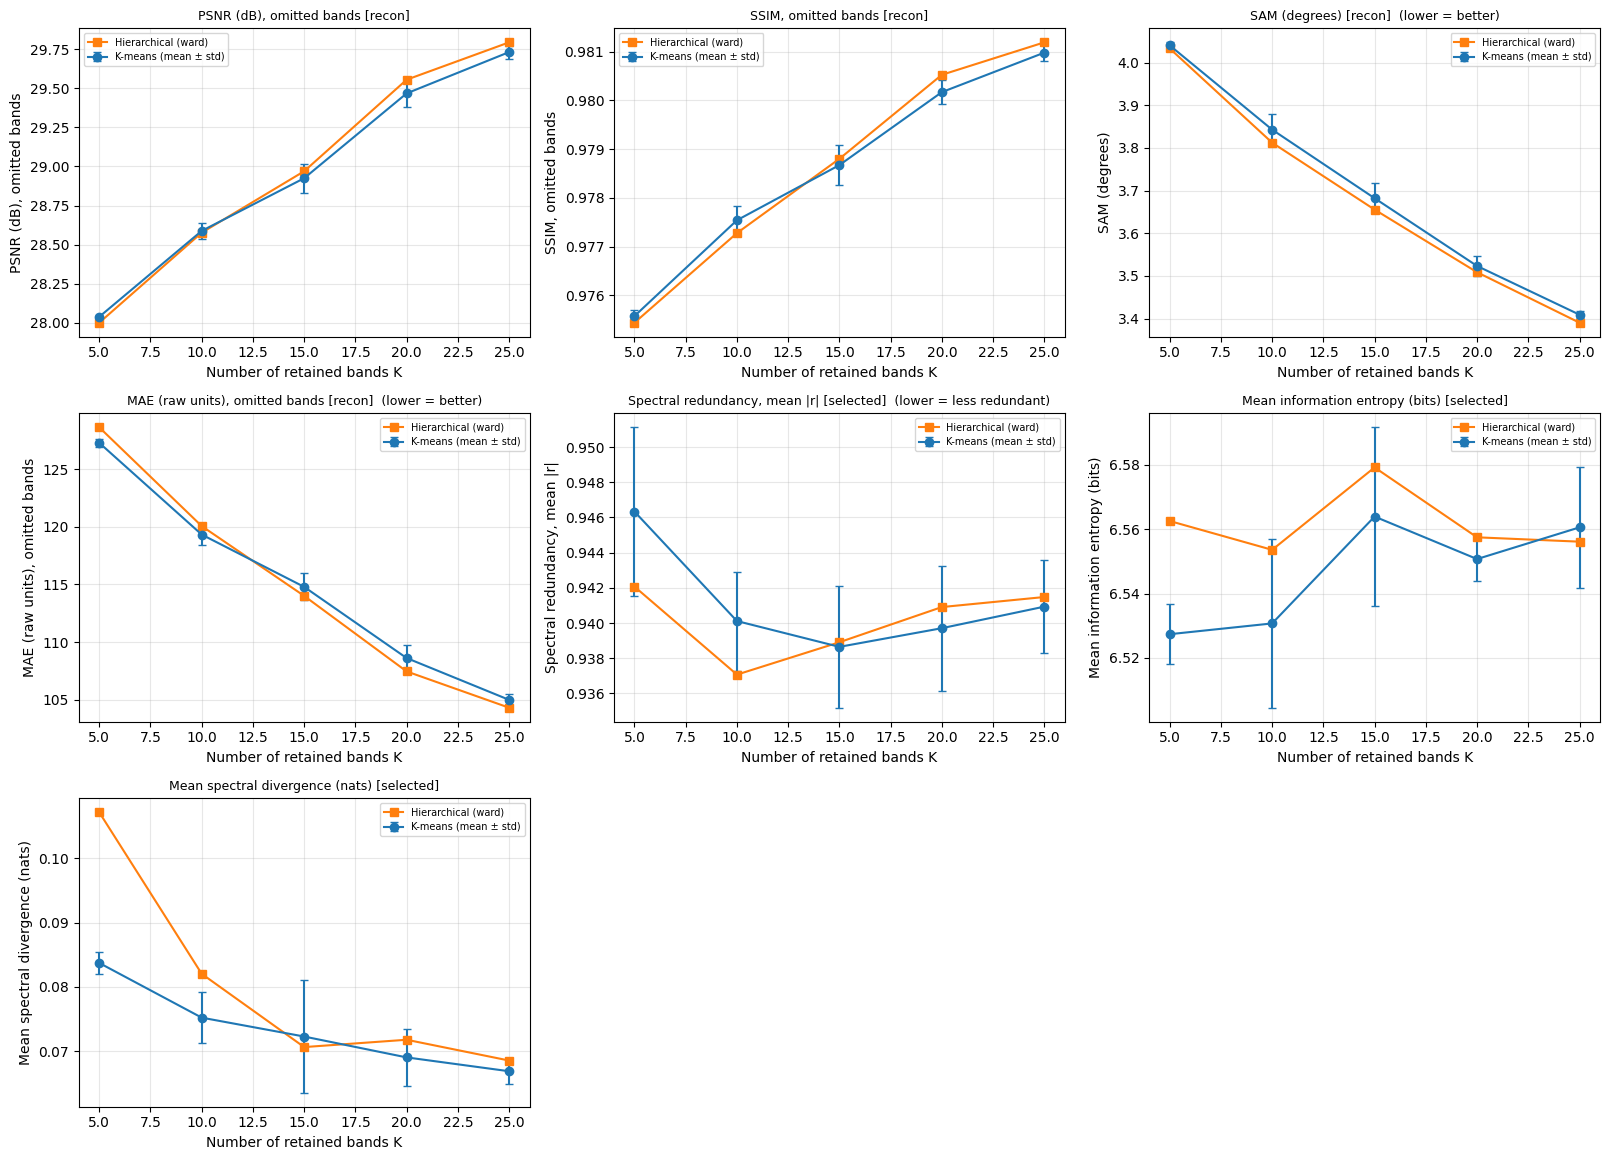

saved: /kaggle/working/hsi_band_selection_outputs/figures/14_compression_vs_quality.png


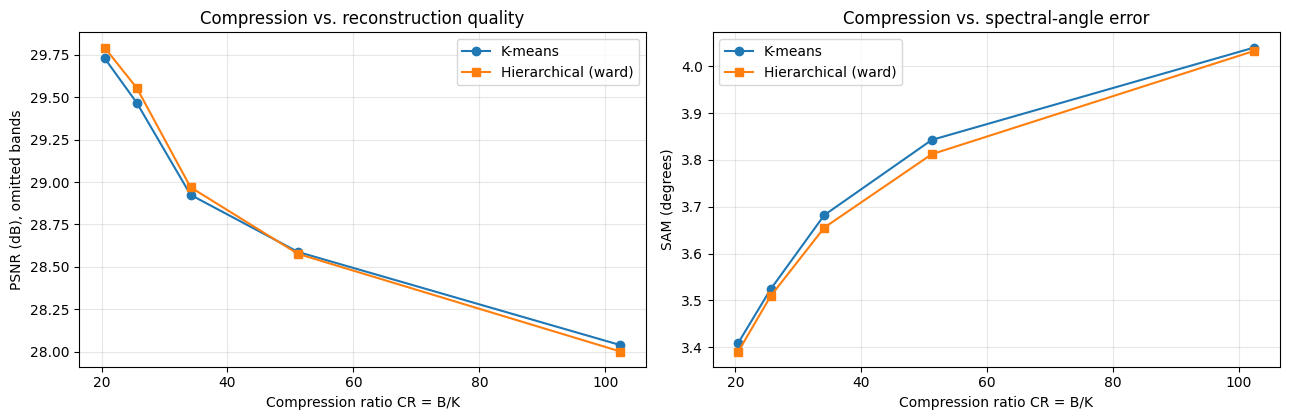

saved: /kaggle/working/hsi_band_selection_outputs/figures/15_runtime_memory.png


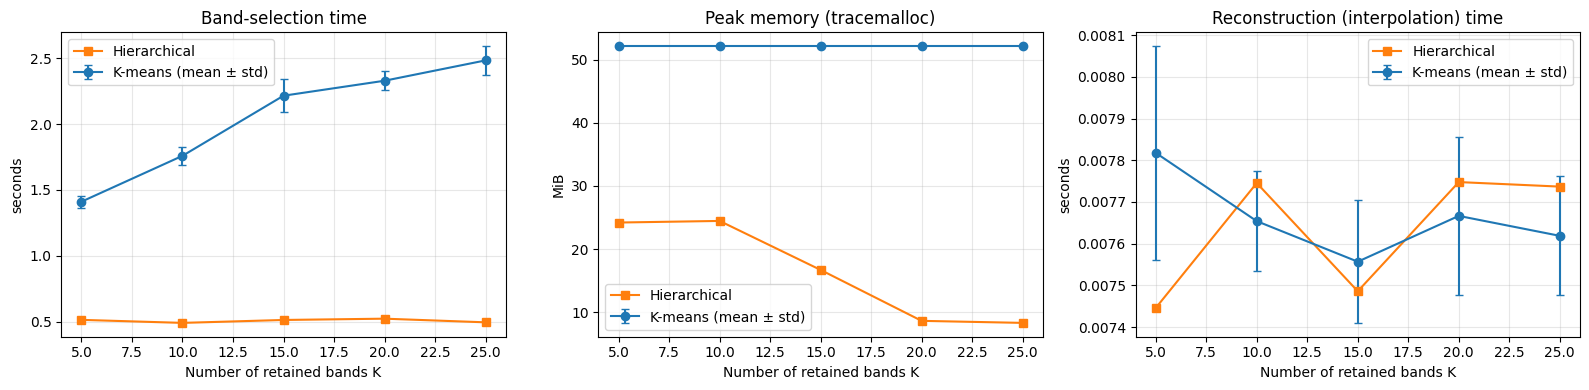

Note: selection time/memory depend on the machine and are measured on the shared feature matrix Z (N_s = 6656 pixels).


In [26]:
def curve(df_fam, col):
    g = df_fam.groupby("K")[col].agg(["mean", "std"]).reindex(K_LIST); return g["mean"].values, g["std"].fillna(0).values
kmp, hcp = prim[prim.family == "kmeans"], prim[prim.family == "hier"]

plot_list = [("PSNR_omitted", "PSNR (dB), omitted bands [recon]", "13b_psnr"), ("SSIM_omitted", "SSIM, omitted bands [recon]", "13c_ssim"),
             ("SAM_deg", "SAM (degrees) [recon]  (lower = better)", "13d_sam"), ("MAE_omitted", "MAE (raw units), omitted bands [recon]  (lower = better)", "13e_mae"),
             ("redundancy", "Spectral redundancy, mean |r| [selected]  (lower = less redundant)", "13f_redundancy"),
             ("entropy_mean", "Mean information entropy (bits) [selected]", "13g_entropy"), ("MSD", "Mean spectral divergence (nats) [selected]", "13h_msd")]
if CLS is not None: plot_list += [("OA", "Overall accuracy [labels]", "13i_oa"), ("AA", "Average accuracy [labels]", "13j_aa"), ("Kappa", "Cohen's kappa [labels]", "13k_kappa")]
n = len(plot_list); ncol = 3; nrow = math.ceil(n / ncol)
fig, axs = plt.subplots(nrow, ncol, figsize=(5.4 * ncol, 3.9 * nrow)); axs = np.atleast_1d(axs).ravel()
for ax, (col, ttl, nm) in zip(axs, plot_list):
    m, s = curve(kmp, col); ax.errorbar(K_LIST, m, yerr=s, marker="o", capsize=3, label="K-means (mean ± std)")
    ax.plot(K_LIST, curve(hcp, col)[0], "s-", label=f"Hierarchical ({CONFIG['primary_linkage']})")
    if col in ("OA", "AA", "Kappa") and BASELINE: ax.axhline(BASELINE[col], color="gray", ls=":", label=f"all {B_V} bands")
    ax.set_xlabel("Number of retained bands K"); ax.set_ylabel(ttl.split(" [")[0]); ax.set_title(ttl, fontsize=9); ax.legend(fontsize=7)
for ax in axs[n:]: ax.axis("off")
plt.tight_layout(); savefig("13_metric_comparison_vs_K"); plt.show()

# compression vs reconstruction quality
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for fam, lab_, mk in ((kmp, "K-means", "o"), (hcp, f"Hierarchical ({CONFIG['primary_linkage']})", "s")):
    g = fam.groupby("K")[["CR", "PSNR_omitted", "SAM_deg"]].mean().reindex(K_LIST)
    ax[0].plot(g.CR, g.PSNR_omitted, mk + "-", label=lab_); ax[1].plot(g.CR, g.SAM_deg, mk + "-", label=lab_)
ax[0].set_xlabel("Compression ratio CR = B/K"); ax[0].set_ylabel("PSNR (dB), omitted bands"); ax[0].set_title("Compression vs. reconstruction quality"); ax[0].legend()
ax[1].set_xlabel("Compression ratio CR = B/K"); ax[1].set_ylabel("SAM (degrees)"); ax[1].set_title("Compression vs. spectral-angle error"); ax[1].legend()
plt.tight_layout(); savefig("14_compression_vs_quality"); plt.show()

# runtime / memory
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for col, a, ttl in (("selection_time_s", ax[0], "Band-selection time"), ("peak_mem_MiB", ax[1], "Peak memory (tracemalloc)"), ("recon_time_s", ax[2], "Reconstruction (interpolation) time")):
    m, s = curve(kmp, col); a.errorbar(K_LIST, m, yerr=s, marker="o", capsize=3, label="K-means (mean ± std)"); a.plot(K_LIST, curve(hcp, col)[0], "s-", label="Hierarchical")
    a.set_xlabel("Number of retained bands K"); a.set_ylabel("seconds" if "time" in col else "MiB"); a.set_title(ttl); a.legend()
plt.tight_layout(); savefig("15_runtime_memory"); plt.show()
print("Note: selection time/memory depend on the machine and are measured on the shared feature matrix Z (N_s =", n_s, "pixels).")

In [27]:
# confusion matrices (reference K) — only if classification was possible
if CLS is not None and KM["cm"].size and HC["cm"].size:
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    for a, res, t, row in ((ax[0], KM, "K-means", km_ref_row), (ax[1], HC, f"Hierarchical ({CONFIG['primary_linkage']})", hc_ref_row)):
        cmn = res["cm"].astype(float); cmn = cmn / np.maximum(cmn.sum(axis=1, keepdims=True), 1)
        im = a.imshow(cmn, vmin=0, vmax=1, cmap="Blues"); a.set_xticks(range(len(CLS["classes"]))); a.set_xticklabels(CLS["classes"]); a.set_yticks(range(len(CLS["classes"]))); a.set_yticklabels(CLS["classes"])
        a.set_xlabel("Predicted class"); a.set_ylabel("True class"); a.set_title(f"{t}, K={K_REF}\nOA={row.OA:.3f}, AA={row.AA:.3f}, kappa={row.Kappa:.3f}"); a.grid(False)
        plt.colorbar(im, ax=a, fraction=0.046, label="row-normalised fraction")
    plt.tight_layout(); savefig("16_confusion_matrices"); plt.show()
else:
    print("Confusion matrices N/A (no classification).")

Confusion matrices N/A (no classification).


## Section 20 — Final findings and limitations

The cell below turns the **measured** table into plain statements. For each metric it says which method is better at each $K$ — but if the difference is smaller than the K-means seed-to-seed standard deviation (or the metric is identical by design, such as CR), it reports a **tie** instead of a winner. It deliberately produces **no overall winner**.

**Standing limitations (apply to every result):**
1. One cube / one dataset: conclusions may not transfer to other scenes or sensors.
2. Reconstruction metrics depend jointly on the selected bands **and** the linear-interpolation baseline, which favours evenly spread bands; they do not measure "clustering quality" in isolation. If wavelengths are missing, even spacing of band indices is assumed.
3. Correlation, entropy, redundancy and MSD are estimated on sampled valid pixels / fixed histograms; they depend on the bin settings.
4. Mean Spectral Divergence follows **our** definition; values are not comparable with other papers' MSD.
5. Classification uses a random pixel split (optimistic due to spatial autocorrelation), one classifier, one split; K-means is repeated over seeds, hierarchical is a single deterministic run.
6. CR depends only on $K$ and the bit depth, so it is identical for both methods by construction.
7. `tracemalloc` memory and wall-clock time are hardware/library dependent.
8. Negative correlations are treated as dissimilar; noisy bands are only flagged, not removed (unless configured).
9. Standard Ward linkage is not WaLuDi/WaLuMI; no claim of reproducing those methods is made.

In [28]:
def verdict(col, K):
    km = prim[(prim.family == "kmeans") & (prim.K == K)][col].astype(float); hc = float(prim[(prim.family == "hier") & (prim.K == K)][col].iloc[0])
    if km.isna().any() or np.isnan(hc): return "N/A"
    m, s = km.mean(), km.std(ddof=0); hib = HIB[col]
    if hib is None or np.isclose(m, hc, rtol=1e-9, atol=1e-12): return "tie/not comparable"
    if abs(m - hc) <= max(s, 1e-12): return "tie (diff <= K-means std)"
    better_km = (m > hc) if hib else (m < hc)
    return "K-means" if better_km else "Hierarchical"

key_cols = ["PSNR_omitted", "SSIM_omitted", "SAM_deg", "MAE_omitted", "MRE_omitted", "redundancy", "entropy_mean", "MSD", "OA", "AA", "Kappa", "selection_time_s", "peak_mem_MiB", "model_state_bytes"]
V = pd.DataFrame({col: [verdict(col, K) for K in K_LIST] for col in key_cols}, index=[f"K={K}" for K in K_LIST]).T
V.to_csv(TAB_DIR / "metric_by_metric_verdicts.csv"); print("Better method per metric and K (measured; ties when within K-means seed variability):\n"); print(V.to_string())
print("\nCounts over all metrics and K values (NOT a scoreboard: metrics are not equally important and several are correlated):")
print(pd.Series(V.values.ravel()).value_counts().to_string())
print("\nNo universal winner is declared. Read the trade-offs: e.g. reconstruction/classification quality vs redundancy vs run time.")

Better method per metric and K (measured; ties when within K-means seed variability):

                                         K=5                       K=10                       K=15                       K=20                       K=25
PSNR_omitted                         K-means  tie (diff <= K-means std)  tie (diff <= K-means std)               Hierarchical               Hierarchical
SSIM_omitted                         K-means                    K-means  tie (diff <= K-means std)               Hierarchical               Hierarchical
SAM_deg                         Hierarchical  tie (diff <= K-means std)  tie (diff <= K-means std)  tie (diff <= K-means std)               Hierarchical
MAE_omitted                          K-means  tie (diff <= K-means std)  tie (diff <= K-means std)               Hierarchical               Hierarchical
MRE_omitted                          K-means  tie (diff <= K-means std)               Hierarchical               Hierarchical               Hierarch

## Section 21 — Exporting selected bands, indices, results, and figures

**What:** save the configuration, environment, selected-band indices (0- and 1-based), reduced cubes ($H\times W\times K$) for the reference $K$, and zip everything for download.
**Output folder structure:**
```
hsi_band_selection_outputs/
├── figures/       *.png         all plots
├── tables/        *.csv/json    band statistics, correlation matrix, diagnostics, all runs, aggregated results, final comparison per K, verdicts
├── selections/    *.npz         per run: labels, representatives, centroids/linkage, per-band errors, confusion matrix
├── cache/<hash>/  *.json        per-run checkpoints (delete this folder to force recomputation)
├── reports/       dataset_inspection_report.json, run_summary.json, README.txt
└── config/        config.json, environment.json
```

In [29]:
# reduced cubes (H x W x K) for the reference K — selected bands are ACTUAL original bands
for name, res in (("kmeans", KM), ("hierarchical", HC)):
    sel = np.sort(res["selected_orig"]); cube_sel = np.moveaxis(XB[sel], 0, 2).astype(ORIG_DTYPE if np.issubdtype(ORIG_DTYPE, np.floating) else np.float32)
    assert cube_sel.shape == (H, W, K_REF)
    assert all(np.array_equal(cube_sel[..., j], XB[b]) for j, b in enumerate(sel[:3])), "reduced cube is not made of original bands"
    np.savez_compressed(SEL_DIR / f"reduced_cube_{name}_K{K_REF}.npz", cube=cube_sel, selected_band_indices_0based=sel)
    print(f"{name}: reduced cube {cube_sel.shape} saved; selected bands (0-based) = {sel.tolist()}")

CFG_OUT = dict(CONFIG, resolved_K_list=K_LIST, K_REF=K_REF, image_file=str(IMG_PATH), valid_band_count=B_V, original_bits=ORIG_BITS,
               data_range_DR=DR, spectral_coordinate=COORD_KIND, n_sampled_pixels=int(n_s), cache_hash=CFG_HASH, data_fingerprint=DATA_FP)
(CFG_DIR / "config.json").write_text(json.dumps(CFG_OUT, indent=2, default=str))
env = dict(python=sys.version, platform=platform.platform(), processor=platform.processor(), cpu_count=os.cpu_count(),
           ram_GiB=round(psutil.virtual_memory().total / 2**30, 2) if psutil else None,
           numpy=np.__version__, scipy=scipy.__version__, sklearn=sklearn.__version__, skimage=skimage.__version__, pandas=pd.__version__, matplotlib=matplotlib.__version__)
(CFG_DIR / "environment.json").write_text(json.dumps(env, indent=2))
(REP_DIR / "run_summary.json").write_text(json.dumps(dict(K_list=K_LIST, n_runs=len(RES), reference_K=K_REF, labels_used_for_classification_only=True,
                                                         reconstruction_method="linear interpolation along " + COORD_KIND), indent=2))
(REP_DIR / "README.txt").write_text(
    "Outputs of the hyperspectral band selection notebook (K-means vs hierarchical clustering).\n"
    "Re-run the notebook top to bottom; finished runs are loaded from cache/. All numbers are measured, none are pre-filled.\n"
    f"Seed={CONFIG['seed']}, K list={K_LIST}, K-means seeds={CONFIG['kmeans_seeds']}.\n")
import shutil
zip_path = shutil.make_archive(str(OUT_ROOT / "hsi_band_selection_results"), "zip", OUT)
print("\nEnvironment:", json.dumps(env, indent=1)); print("\nZipped results ->", zip_path)
print("Files saved (excluding cache):", sum(1 for p in OUT.rglob('*') if p.is_file() and 'cache' not in p.parts))

kmeans: reduced cube (13, 512, 15) saved; selected bands (0-based) = [18, 48, 93, 103, 108, 122, 136, 164, 174, 193, 204, 215, 232, 267, 369]
hierarchical: reduced cube (13, 512, 15) saved; selected bands (0-based) = [17, 50, 93, 104, 122, 149, 156, 172, 193, 202, 215, 232, 267, 368, 459]

Environment: {
 "python": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
 "platform": "Linux-6.18.55+-x86_64-with-glibc2.39",
 "processor": "x86_64",
 "cpu_count": 4,
 "ram_GiB": 31.35,
 "numpy": "2.1.3",
 "scipy": "1.16.3",
 "sklearn": "1.6.1",
 "skimage": "0.25.2",
 "pandas": "2.3.3",
 "matplotlib": "3.10.0"
}

Zipped results -> /kaggle/working/hsi_band_selection_results.zip
Files saved (excluding cache): 110


## Reproducibility checklist
* Fixed seeds: pixel sampling (`seed`), K-means (`kmeans_seeds`), data split (`seed`). K-means is *repeated* over seeds; hierarchical clustering has no randomness.
* Same $Z$, same valid-band policy, same $K$ list, same reconstruction baseline, same fixed DR, same classifier/split for every method.
* Everything needed to rerun is in `config/config.json` and `config/environment.json`.
* Only the 0-based band index is used inside the code; 1-based indices are also exported for users who count bands from 1.

**What would change if the dataset differs from expectations:** the discovery section prints the real structure; adjust `CONFIG` (file, axis order, label path/key, wavelengths) rather than editing algorithm code.